# E-Commerce Customer Behavior Analysis

## 1. Environment Setup and Data Loading

In [1]:
from pathlib import Path
import os, sys, json, hashlib, warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    roc_auc_score, average_precision_score, balanced_accuracy_score, accuracy_score,
    precision_score, recall_score, f1_score, confusion_matrix, brier_score_loss,
    log_loss, precision_recall_curve, roc_curve, auc
)
from IPython.display import display, Markdown

try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except (NameError, AttributeError):
    pass

pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 95)
pd.set_option('display.width', 180)

DATA_DIR = Path(os.environ.get('ECOM_DATA_DIR', 'data'))
if not (DATA_DIR / 'ecommerce_customer_behavior_dataset.xlsx').is_file() and Path('ecommerce_customer_behavior_dataset.xlsx').is_file():
    DATA_DIR = Path('.')
DATA_FILE = os.environ.get('ECOM_DATA_FILE', 'ecommerce_customer_behavior_dataset.xlsx')
OUTPUT_DIR = Path(os.environ.get('ECOM_OUTPUT_DIR', 'outputs'))

for folder in ['tables', 'figures']:
    (OUTPUT_DIR / folder).mkdir(parents=True, exist_ok=True)

EXPECTED_SHA256 = 'c94e0930eaf59562daf6da3a4dd1dc04b0632d0384a377185ea8f3e46fbfb959'
EXPECTED_SHEET = 'CustBehavior'
EXPECTED_COLUMNS = [
    'Order_ID', 'Customer_ID', 'Date', 'Age', 'Gender', 'City', 'Product_Category',
    'Unit_Price', 'Quantity', 'Discount_Amount', 'Total_Amount', 'Payment_Method',
    'Device_Type', 'Session_Duration_Minutes', 'Pages_Viewed', 'Is_Returning_Customer',
    'Delivery_Time_Days', 'Customer_Rating'
]

SEED = 42
ALPHA = 0.05
BOOTSTRAPS = 3000
MODEL_BOOTSTRAPS = 1500
FORECAST_HORIZON = 8

TABLES, FIGURES, WARNING_LOG = {}, [], []

def save_table(name, frame, description, show=True):
    if not isinstance(frame, pd.DataFrame):
        frame = pd.DataFrame(frame)
    frame = frame.reset_index(drop=True)
    frame.to_csv(OUTPUT_DIR / 'tables' / f'{name}.csv', index=False, float_format='%.15g')
    TABLES[name] = frame
    if show:
        display(Markdown(f'**{name}** — {description}'))
        display(frame if len(frame) <= 18 else frame.head(18))
    return frame

def save_figure(name, description):
    fig = plt.gcf()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / 'figures' / f'{name}.png', dpi=170, bbox_inches='tight')
    FIGURES.append({'figure': name, 'description': description, 'path': f'figures/{name}.png'})
    plt.show()
    plt.close(fig)

def checked_fit(estimator, X, y, context):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        estimator.fit(X, y)
    for w in caught:
        WARNING_LOG.append({'context': context, 'category': w.category.__name__, 'message': str(w.message)})
    return estimator

def bh_q(values):
    return multipletests(np.asarray(values, dtype=float), alpha=ALPHA, method='fdr_bh')[1]

def bootstrap_difference(a, b, repetitions=BOOTSTRAPS, seed=SEED):
    a, b = np.asarray(a, float), np.asarray(b, float)
    rng = np.random.default_rng(seed)
    draws = np.empty(repetitions)
    for i in range(repetitions):
        draws[i] = rng.choice(a, len(a), replace=True).mean() - rng.choice(b, len(b), replace=True).mean()
    return np.quantile(draws, [.025, .975])

DATA_PATH = (DATA_DIR / DATA_FILE).resolve()
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Dataset not found at {DATA_PATH}')
if hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() != EXPECTED_SHA256:
    raise ValueError('Source SHA-256 mismatch.')

excel = pd.ExcelFile(DATA_PATH)
if excel.sheet_names != [EXPECTED_SHEET]:
    raise ValueError(f'Unexpected workbook sheets: {excel.sheet_names}')
source_df = pd.read_excel(DATA_PATH, sheet_name=EXPECTED_SHEET)
if source_df.shape != (5000, 18) or list(source_df.columns) != EXPECTED_COLUMNS:
    raise ValueError(f'Unexpected schema: {source_df.shape}')

df = source_df.copy(deep=True)
NUMERIC = df.select_dtypes(include='number').columns.tolist()
CATEGORICAL = ['Gender', 'City', 'Product_Category', 'Payment_Method', 'Device_Type', 'Is_Returning_Customer']
print(f'Loaded {len(df):,} rows and {len(df.columns)} columns from {DATA_PATH.name}')

Loaded 5,000 rows and 18 columns from ecommerce_customer_behavior_dataset.xlsx


## 2. Data Quality and Accounting Identity Audit

In [2]:
summary = [
    ('rows', len(df)), ('columns', len(df.columns)),
    ('unique_orders', df.Order_ID.nunique()), ('unique_customers', df.Customer_ID.nunique()),
    ('repeat_observed_customers', int((df.groupby('Customer_ID').size() > 1).sum())),
    ('unique_dates', df.Date.nunique()),
    ('date_min', df.Date.min().date().isoformat()), ('date_max', df.Date.max().date().isoformat()),
    ('missing_cells', int(df.isna().sum().sum())), ('duplicate_rows', int(df.duplicated().sum())),
    ('returning_flag_true', int(df.Is_Returning_Customer.sum())),
    ('returning_flag_share', df.Is_Returning_Customer.mean()),
    ('observed_total_value', df.Total_Amount.sum()),
    ('mean_order_value', df.Total_Amount.mean()), ('median_order_value', df.Total_Amount.median()),
    ('discounted_orders', int((df.Discount_Amount > 0).sum())),
    ('discounted_order_share', (df.Discount_Amount > 0).mean()),
    ('discount_total', df.Discount_Amount.sum()),
    ('mean_delivery_days', df.Delivery_Time_Days.mean()), ('median_delivery_days', df.Delivery_Time_Days.median())
]
source_summary = save_table('01_source_summary', pd.DataFrame(summary, columns=['metric', 'value']), 'Source dataset headline metrics.')

checks = []
def check(name, count):
    checks.append({'check': name, 'flag_count': int(count), 'status': 'PASS' if count == 0 else 'REVIEW'})

check('Missing cells', df.isna().sum().sum())
check('Exact duplicate rows', df.duplicated().sum())
for key in ['Order_ID', 'Customer_ID']:
    check(f'Duplicate {key}', df[key].duplicated().sum())
    check(f'Malformed {key}', (~df[key].str.fullmatch('ORD_[0-9]{6}' if key == 'Order_ID' else 'CUST_[0-9]{5}')).sum())
for col in NUMERIC:
    check(f'Nonfinite {col}', (~np.isfinite(df[col])).sum())
for col in ['Unit_Price', 'Total_Amount', 'Quantity', 'Session_Duration_Minutes', 'Pages_Viewed', 'Delivery_Time_Days']:
    check(f'Nonpositive {col}', (df[col] <= 0).sum())
check('Negative discount', (df.Discount_Amount < 0).sum())
check('Discount exceeds gross amount', (df.Discount_Amount > df.Unit_Price * df.Quantity).sum())
check('Rating outside 1-5', (~df.Customer_Rating.between(1, 5)).sum())
check('Age outside 0-120', (~df.Age.between(0, 120)).sum())
check('Missing calendar dates', len(pd.date_range(df.Date.min(), df.Date.max()).difference(pd.DatetimeIndex(df.Date.unique()))))
quality = save_table('02_data_quality_checks', pd.DataFrame(checks), 'Structural validity and range checks.')

identity_residual = df.Total_Amount - (df.Unit_Price * df.Quantity - df.Discount_Amount)
identity = save_table('03_accounting_identity', pd.DataFrame([
    {'metric': 'rows_matching_within_1e-6', 'value': int((identity_residual.abs() <= 1e-6).sum())},
    {'metric': 'max_absolute_residual', 'value': identity_residual.abs().max()},
    {'metric': 'gross_amount', 'value': (df.Unit_Price * df.Quantity).sum()},
    {'metric': 'discount_amount', 'value': df.Discount_Amount.sum()},
    {'metric': 'net_amount', 'value': df.Total_Amount.sum()},
    {'metric': 'order_customer_suffix_matches', 'value': int((df.Order_ID.str.extract('([0-9]+)')[0].astype(int) == df.Customer_ID.str.extract('([0-9]+)')[0].astype(int)).sum())}
]), 'Verification of Total_Amount = Unit_Price * Quantity - Discount_Amount.')

**01_source_summary** — Source dataset headline metrics.

,metric,value
0,rows,5000
1,columns,18
2,unique_orders,5000
3,unique_customers,5000
4,repeat_observed_customers,0
5,unique_dates,451
6,date_min,2023-01-01
7,date_max,2024-03-26
8,missing_cells,0
9,duplicate_rows,0


**02_data_quality_checks** — Structural validity and range checks.

,check,flag_count,status
0,Missing cells,0,PASS
1,Exact duplicate rows,0,PASS
2,Duplicate Order_ID,0,PASS
3,Malformed Order_ID,0,PASS
4,Duplicate Customer_ID,0,PASS
5,Malformed Customer_ID,0,PASS
6,Nonfinite Age,0,PASS
7,Nonfinite Unit_Price,0,PASS
8,Nonfinite Quantity,0,PASS
9,Nonfinite Discount_Amount,0,PASS


**03_accounting_identity** — Verification of Total_Amount = Unit_Price * Quantity - Discount_Amount.

,metric,value
0,rows_matching_within_1e-6,5.000000e+03
1,max_absolute_residual,3.637979e-12
2,gross_amount,5.039809e+06
3,discount_amount,1.242640e+05
4,net_amount,4.915545e+06
5,order_customer_suffix_matches,5.000000e+03


## 3. Descriptive Distributions, Outlier Audit, and Value Concentration

**04_numeric_descriptives** — Numeric summary statistics and skewness.

,variable,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skewness,iqr
0,Age,5000.0,35.032600,11.080546,18.00,18.0000,18.0000,27.0000,35.00,42.000,54.0000,62.0000,75.00,0.335670,15.0000
1,Unit_Price,5000.0,455.834120,712.477209,5.18,17.0188,27.9440,76.5875,182.95,513.930,1837.1635,3629.9912,7159.45,3.471454,437.3425
2,Quantity,5000.0,2.220000,1.398711,1.00,1.0000,1.0000,1.0000,2.00,3.000,5.0000,5.0000,5.00,0.824779,2.0000
3,Discount_Amount,5000.0,24.852804,88.385124,0.00,0.0000,0.0000,0.0000,0.00,8.760,129.1895,422.0714,1525.55,7.401594,8.7600
4,Total_Amount,5000.0,983.108914,1898.978528,7.87,19.6898,36.7745,122.5175,337.91,979.695,4051.0840,9879.9478,22023.90,4.895841,857.1775
5,Session_Duration_Minutes,5000.0,14.573400,8.665750,1.00,2.0000,4.0000,8.0000,13.00,19.000,31.0000,42.0000,73.00,1.160301,11.0000
6,Pages_Viewed,5000.0,8.984200,2.804340,1.00,3.0000,5.0000,7.0000,9.00,11.000,14.0000,16.0000,24.00,0.371004,4.0000
7,Delivery_Time_Days,5000.0,6.497000,3.464966,1.00,1.0000,2.0000,4.0000,6.00,8.000,13.0000,17.0000,25.00,1.110639,4.0000
8,Customer_Rating,5000.0,3.902800,1.128542,1.00,1.0000,2.0000,3.0000,4.00,5.000,5.0000,5.0000,5.00,-0.948843,2.0000


**05_outlier_audit** — IQR outlier screening (all records retained).

,variable,q1,q3,lower_fence,upper_fence,flag_count,flag_share
0,Age,27.0000,42.000,4.50000,64.50000,30,0.0060
1,Unit_Price,76.5875,513.930,-579.42625,1169.94375,513,0.1026
2,Quantity,1.0000,3.000,-2.00000,6.00000,0,0.0000
3,Discount_Amount,0.0000,8.760,-13.14000,21.90000,879,0.1758
4,Total_Amount,122.5175,979.695,-1163.24875,2265.46125,546,0.1092
5,Session_Duration_Minutes,8.0000,19.000,-8.50000,35.50000,124,0.0248
6,Pages_Viewed,7.0000,11.000,1.00000,17.00000,14,0.0028
7,Delivery_Time_Days,4.0000,8.000,-2.00000,14.00000,141,0.0282
8,Customer_Rating,3.0000,5.000,0.00000,8.00000,0,0.0000


**06_category_profiles** — Nominal profiles across dimensions.

,dimension,category,orders,total_value,mean_value,median_value,mean_unit_price,mean_quantity,mean_discount,mean_session,mean_pages,mean_delivery,mean_rating,order_share,value_share
0,Gender,Female,2492,2474009.26,992.780602,344.535,464.829390,2.221108,25.186629,14.781300,8.936998,6.392055,3.887239,0.4984,0.503303
1,Gender,Male,2435,2381028.70,977.835195,333.200,448.299092,2.212320,24.753372,14.346201,9.030801,6.618070,3.921150,0.4870,0.484388
2,Gender,Other,73,60506.61,828.857671,265.450,400.102329,2.438356,16.773699,15.054795,9.041096,6.041096,3.821918,0.0146,0.012309
3,City,Adana,378,427059.63,1129.787381,350.300,565.307989,2.111111,29.066085,15.394180,9.039683,6.611111,3.917989,0.0756,0.086879
4,City,Ankara,735,657535.82,894.606558,311.800,426.457619,2.242177,22.789034,14.674830,9.119728,6.549660,3.878912,0.1470,0.133767
5,City,Antalya,374,315549.89,843.716283,270.790,363.265160,2.144385,24.785829,13.871658,8.973262,6.422460,3.844920,0.0748,0.064194
6,City,Bursa,496,459076.31,925.557077,367.710,432.112157,2.322581,24.224758,14.372984,8.931452,6.395161,3.939516,0.0992,0.093393
7,City,Eskisehir,210,178978.43,852.278238,351.725,446.971095,2.180952,25.776905,15.128571,9.104762,6.628571,3.828571,0.0420,0.036411
8,City,Gaziantep,349,318408.41,912.345014,304.150,420.360516,2.157593,23.186218,14.693410,8.957020,6.275072,3.954155,0.0698,0.064776
9,City,Istanbul,1284,1334122.56,1039.036262,346.995,450.218185,2.292835,23.490202,14.523364,8.922897,6.670561,3.887072,0.2568,0.271409


**07_value_concentration** — Order-level value concentration.

,metric,orders,order_share,total_value,value_share
0,top_1_percent,50,0.0100,703406.45,0.143098
1,top_5_percent,250,0.0500,1891311.13,0.384761
2,top_10_percent,500,0.1000,2679193.94,0.545045
3,top_20_percent,1000,0.2000,3541278.46,0.720424
4,top_25_percent,1250,0.2500,3819271.18,0.776978
5,minimum_orders_reaching_80_percent_value,1373,0.2746,3933281.45,0.800172


**08_transaction_value_tiers** — Transaction value quartiles.

,Value_Tier,orders,total_value,mean_value,median_value,mean_quantity,mean_delivery,mean_session,mean_pages,mean_rating,returning_flag_share,lower_boundary,upper_boundary,order_share,value_share
0,Q1 lowest,1250,84281.60,67.425280,65.965,1.3960,6.5336,14.4960,8.9040,3.9120,0.5864,7.8700,122.5175,0.25,0.017146
1,Q2,1250,269437.95,215.550360,209.230,2.0760,6.4376,14.7656,9.1568,3.9104,0.5920,122.5175,337.9100,0.25,0.054813
2,Q3,1250,742553.84,594.043072,566.010,2.4384,6.5032,14.4184,8.9216,3.8760,0.6032,337.9100,979.6950,0.25,0.151062
3,Q4 highest,1250,3819271.18,3055.416944,1989.075,2.9696,6.5136,14.6136,8.9544,3.9128,0.6104,979.6950,22023.9000,0.25,0.776978


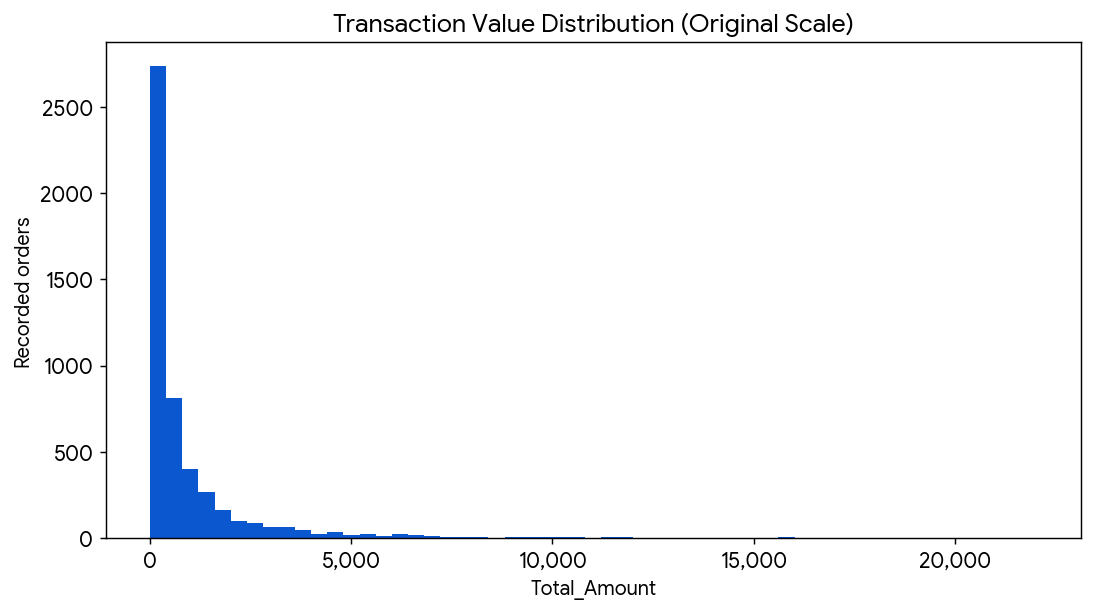

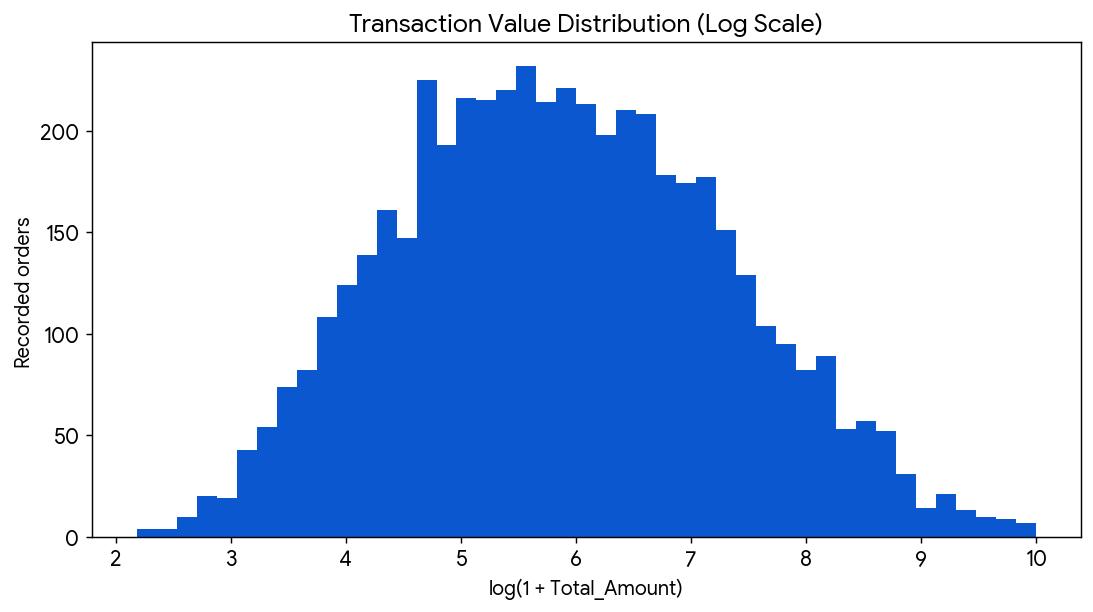

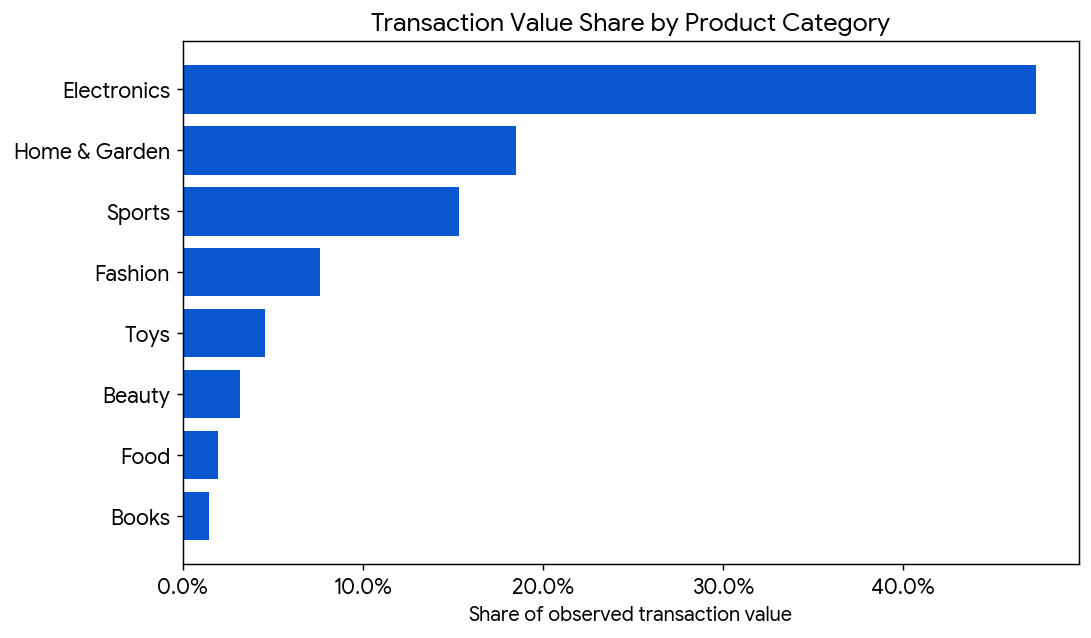

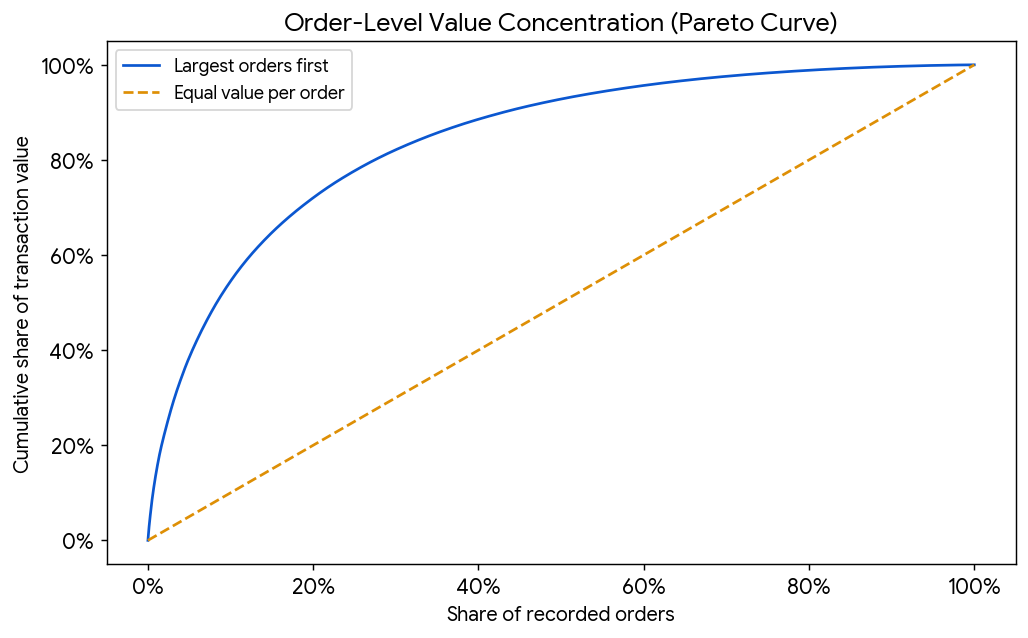

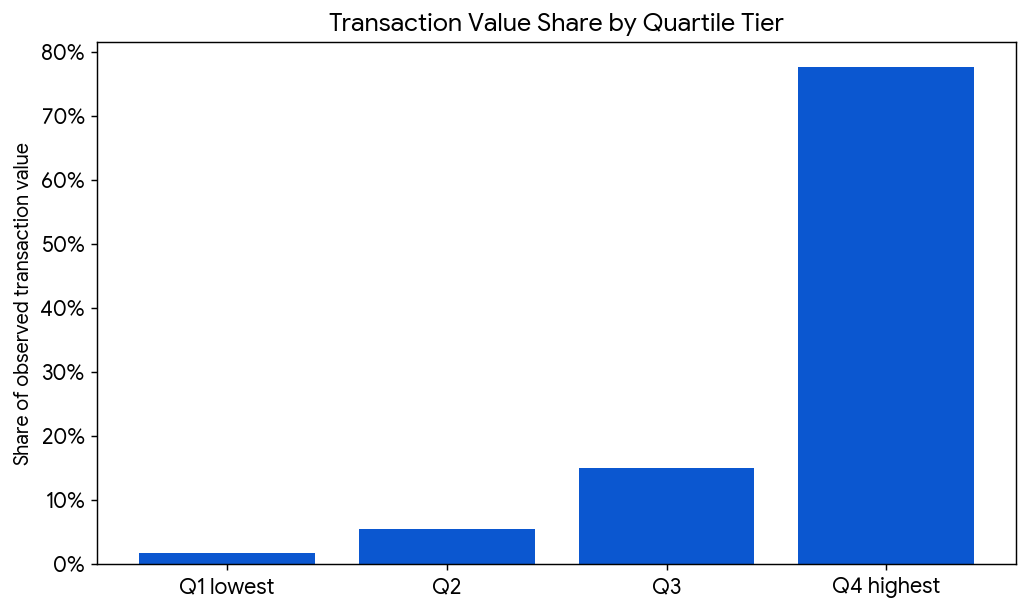

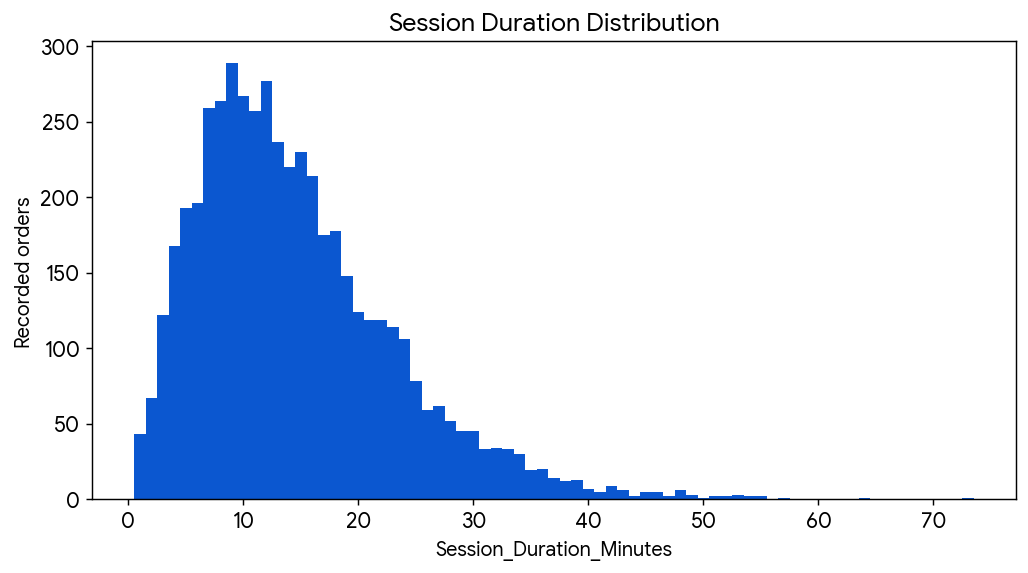

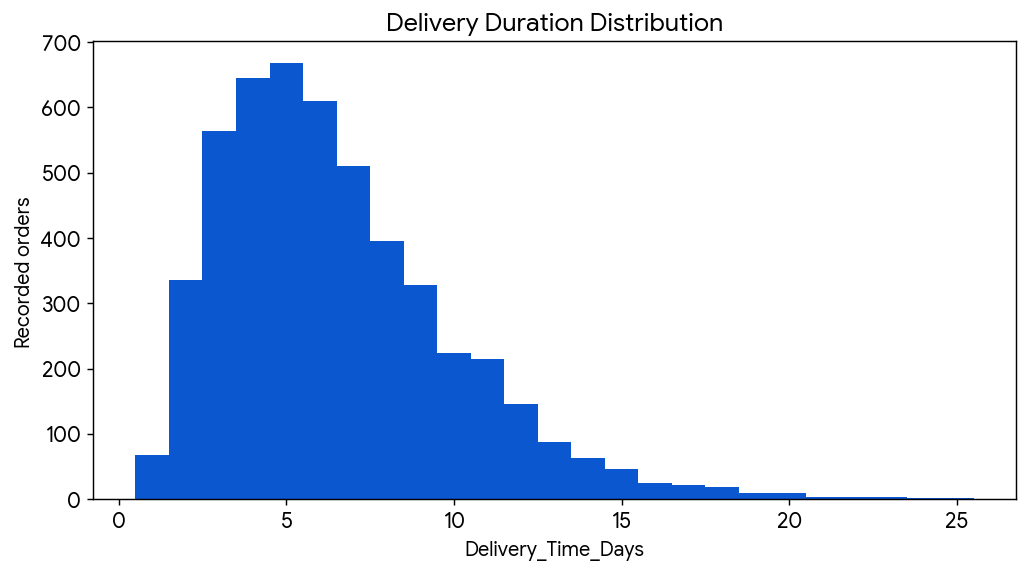

In [3]:
work = df.assign(Gross_Amount=df.Unit_Price * df.Quantity, Discounted=df.Discount_Amount.gt(0))
work['Discount_Rate'] = work.Discount_Amount / work.Gross_Amount

desc = df[NUMERIC].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T.reset_index(names='variable')
desc['skewness'] = [df[c].skew() for c in desc.variable]
desc['iqr'] = desc['75%'] - desc['25%']
descriptive = save_table('04_numeric_descriptives', desc, 'Numeric summary statistics and skewness.')

outlier_rows = []
for c in NUMERIC:
    q1, q3 = df[c].quantile([.25, .75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    flags = (df[c] < lo) | (df[c] > hi)
    outlier_rows.append({'variable': c, 'q1': q1, 'q3': q3, 'lower_fence': lo, 'upper_fence': hi, 'flag_count': int(flags.sum()), 'flag_share': flags.mean()})
outliers = save_table('05_outlier_audit', pd.DataFrame(outlier_rows), 'IQR outlier screening (all records retained).')

profiles = []
for c in CATEGORICAL:
    g = df.groupby(c, observed=True).agg(
        orders=('Order_ID', 'size'), total_value=('Total_Amount', 'sum'),
        mean_value=('Total_Amount', 'mean'), median_value=('Total_Amount', 'median'),
        mean_unit_price=('Unit_Price', 'mean'), mean_quantity=('Quantity', 'mean'),
        mean_discount=('Discount_Amount', 'mean'), mean_session=('Session_Duration_Minutes', 'mean'),
        mean_pages=('Pages_Viewed', 'mean'), mean_delivery=('Delivery_Time_Days', 'mean'),
        mean_rating=('Customer_Rating', 'mean')
    ).reset_index().rename(columns={c: 'category'})
    g['category'] = g['category'].astype(str)
    g.insert(0, 'dimension', c)
    g['order_share'] = g.orders / len(df)
    g['value_share'] = g.total_value / df.Total_Amount.sum()
    profiles.append(g)
category_profiles = save_table('06_category_profiles', pd.concat(profiles, ignore_index=True), 'Nominal profiles across dimensions.')
product_profile = category_profiles.query('dimension == "Product_Category"').sort_values('total_value', ascending=False).reset_index(drop=True)

sorted_value = df.Total_Amount.sort_values(ascending=False).reset_index(drop=True)
curve = pd.DataFrame({'rank': np.arange(1, len(df) + 1), 'value': sorted_value})
curve['order_share'] = curve['rank'] / len(df)
curve['cumulative_value'] = curve.value.cumsum()
curve['cumulative_value_share'] = curve.cumulative_value / curve.value.sum()

concentration_rows = []
for fraction in [.01, .05, .10, .20, .25]:
    n = int(math.ceil(fraction * len(df)))
    concentration_rows.append({
        'metric': f'top_{int(fraction*100)}_percent', 'orders': n, 'order_share': n / len(df),
        'total_value': sorted_value.iloc[:n].sum(), 'value_share': sorted_value.iloc[:n].sum() / sorted_value.sum()
    })
n80 = int(np.searchsorted(curve.cumulative_value_share.to_numpy(), .80) + 1)
concentration_rows.append({
    'metric': 'minimum_orders_reaching_80_percent_value', 'orders': n80, 'order_share': n80 / len(df),
    'total_value': sorted_value.iloc[:n80].sum(), 'value_share': sorted_value.iloc[:n80].sum() / sorted_value.sum()
})
concentration = save_table('07_value_concentration', pd.DataFrame(concentration_rows), 'Order-level value concentration.')

work['Value_Tier'], tier_edges = pd.qcut(work.Total_Amount, q=4, labels=['Q1 lowest', 'Q2', 'Q3', 'Q4 highest'], retbins=True)
tiers = work.groupby('Value_Tier', observed=True).agg(
    orders=('Order_ID', 'size'), total_value=('Total_Amount', 'sum'),
    mean_value=('Total_Amount', 'mean'), median_value=('Total_Amount', 'median'),
    mean_quantity=('Quantity', 'mean'), mean_delivery=('Delivery_Time_Days', 'mean'),
    mean_session=('Session_Duration_Minutes', 'mean'), mean_pages=('Pages_Viewed', 'mean'),
    mean_rating=('Customer_Rating', 'mean'), returning_flag_share=('Is_Returning_Customer', 'mean')
).reset_index()
tiers['Value_Tier'] = tiers.Value_Tier.astype(str)
tiers['lower_boundary'] = tier_edges[:-1]
tiers['upper_boundary'] = tier_edges[1:]
tiers['order_share'] = tiers.orders / len(df)
tiers['value_share'] = tiers.total_value / df.Total_Amount.sum()
tiers = save_table('08_transaction_value_tiers', tiers, 'Transaction value quartiles.')

plt.figure(figsize=(8.5, 4.8))
plt.hist(df.Total_Amount, bins=55)
plt.xlabel('Total_Amount')
plt.ylabel('Recorded orders')
plt.title('Transaction Value Distribution (Original Scale)')
plt.gca().xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
save_figure('01_value_distribution', 'Untrimmed distribution of net transaction amount.')

plt.figure(figsize=(8.5, 4.8))
plt.hist(np.log1p(df.Total_Amount), bins=45)
plt.xlabel('log(1 + Total_Amount)')
plt.ylabel('Recorded orders')
plt.title('Transaction Value Distribution (Log Scale)')
save_figure('02_log_value_distribution', 'Log-transformed view of net transaction amount.')

plt.figure(figsize=(8.5, 5.0))
p = product_profile.sort_values('value_share')
plt.barh(p.category, p.value_share)
plt.gca().xaxis.set_major_formatter(PercentFormatter(1))
plt.xlabel('Share of observed transaction value')
plt.title('Transaction Value Share by Product Category')
save_figure('03_category_value_share', 'Value share across product categories.')

plt.figure(figsize=(8, 5))
plt.plot(np.r_[0, curve.order_share], np.r_[0, curve.cumulative_value_share], label='Largest orders first')
plt.plot([0, 1], [0, 1], linestyle='--', label='Equal value per order')
plt.xlabel('Share of recorded orders')
plt.ylabel('Cumulative share of transaction value')
plt.gca().xaxis.set_major_formatter(PercentFormatter(1))
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.title('Order-Level Value Concentration (Pareto Curve)')
plt.legend()
save_figure('04_value_concentration', 'Order-level value concentration curve.')

plt.figure(figsize=(8, 4.8))
plt.bar(tiers.Value_Tier, tiers.value_share)
plt.ylabel('Share of observed transaction value')
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.title('Transaction Value Share by Quartile Tier')
save_figure('05_value_tiers', 'Value share by transaction quartile.')

for c, title in [('Session_Duration_Minutes', 'Session Duration Distribution'), ('Delivery_Time_Days', 'Delivery Duration Distribution')]:
    plt.figure(figsize=(8, 4.5))
    plt.hist(df[c], bins=np.arange(df[c].min() - .5, df[c].max() + 1.5))
    plt.xlabel(c)
    plt.ylabel('Recorded orders')
    plt.title(title)
    save_figure(f'06_distribution_{c}', f'Distribution of {c}.')

## 4. Spearman Rank Correlation Analysis

**10_spearman_pairs** — Pairwise Spearman correlations with BH-FDR adjustment.

,variable_a,variable_b,rho,abs_rho,p_value,q_bh,accounting_linked
0,Unit_Price,Total_Amount,0.891947,0.891947,NaN,NaN,True
1,Quantity,Total_Amount,0.438667,0.438667,NaN,NaN,True
2,Unit_Price,Discount_Amount,0.120195,0.120195,1.490130e-17,4.917428e-16,False
3,Discount_Amount,Total_Amount,0.068129,0.068129,NaN,NaN,True
4,Discount_Amount,Session_Duration_Minutes,0.027200,0.027200,5.445262e-02,7.835851e-01,False
5,Discount_Amount,Customer_Rating,0.023512,0.023512,9.643334e-02,7.835851e-01,False
6,Session_Duration_Minutes,Pages_Viewed,0.023279,0.023279,9.978639e-02,7.835851e-01,False
7,Session_Duration_Minutes,Customer_Rating,0.019611,0.019611,1.655866e-01,7.835851e-01,False
8,Quantity,Customer_Rating,-0.018983,0.018983,1.795744e-01,7.835851e-01,False
9,Discount_Amount,Pages_Viewed,0.017863,0.017863,2.066262e-01,7.835851e-01,False


**11_spearman_selected_ci** — 95% bootstrap confidence intervals for selected pairs.

,variable_a,variable_b,rho,ci_low,ci_high
0,Unit_Price,Total_Amount,0.891947,0.886341,0.896789
1,Quantity,Total_Amount,0.438667,0.416878,0.460803
2,Unit_Price,Discount_Amount,0.120195,0.089527,0.146877
3,Session_Duration_Minutes,Pages_Viewed,0.023279,-0.002827,0.053428
4,Delivery_Time_Days,Customer_Rating,-0.015724,-0.043180,0.010803


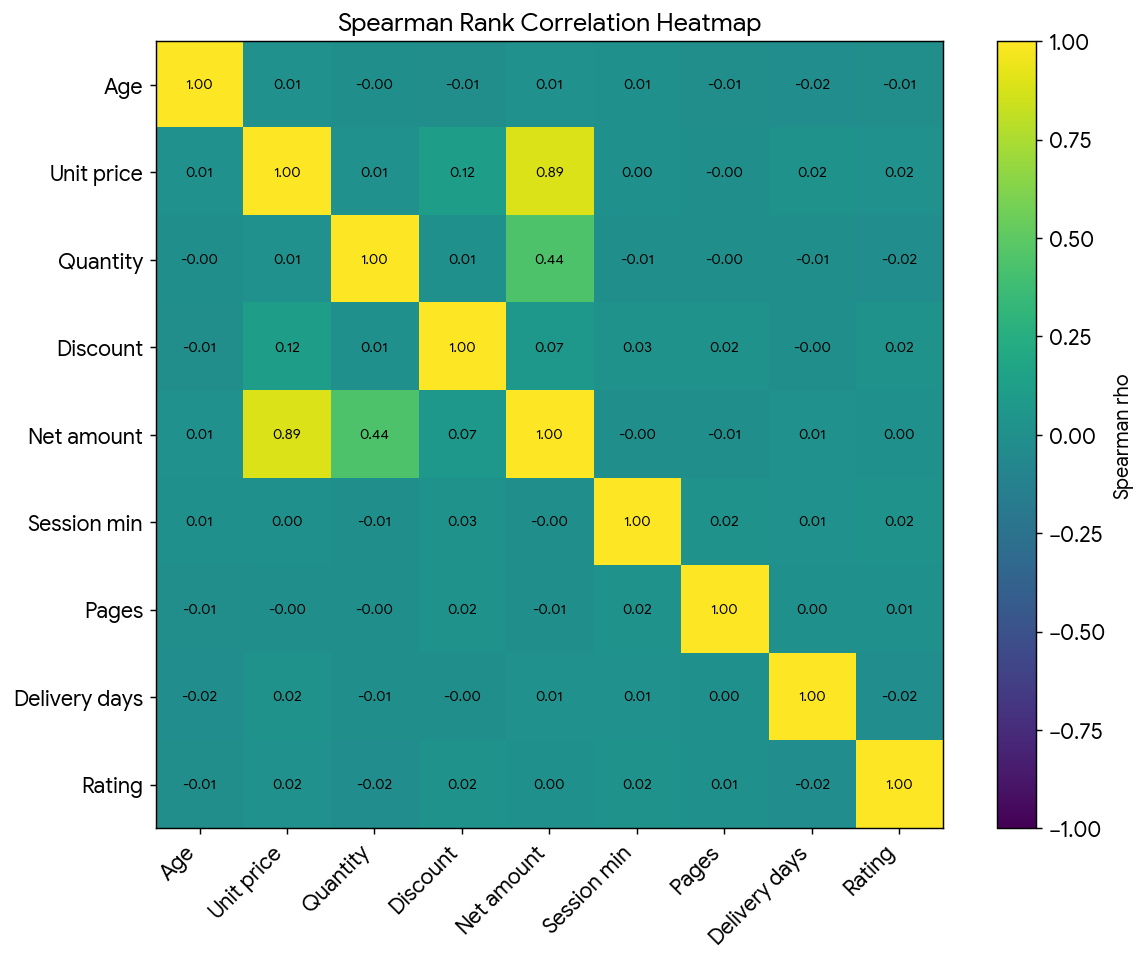

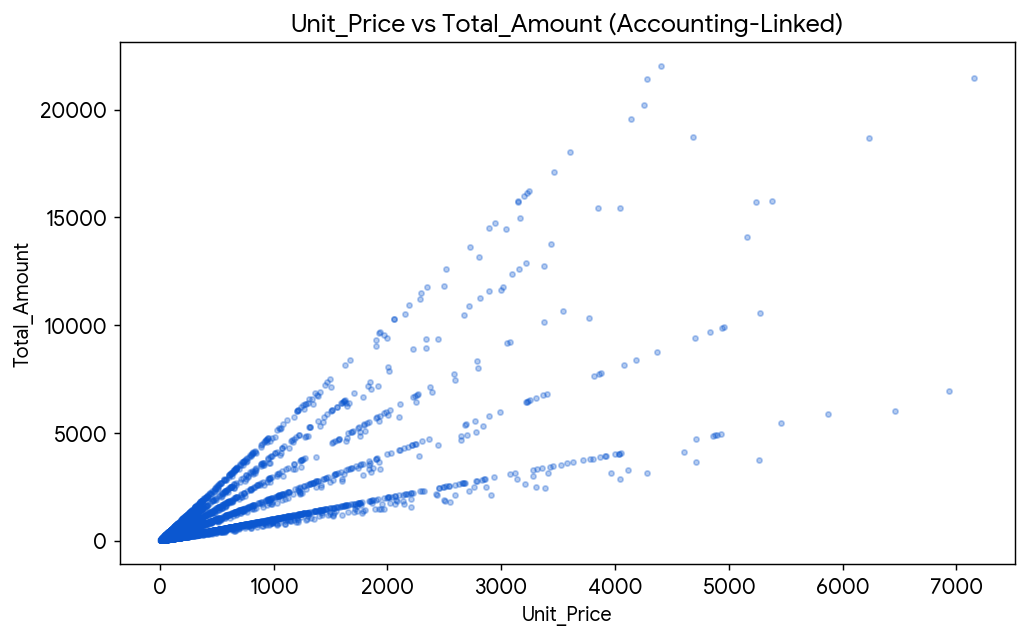

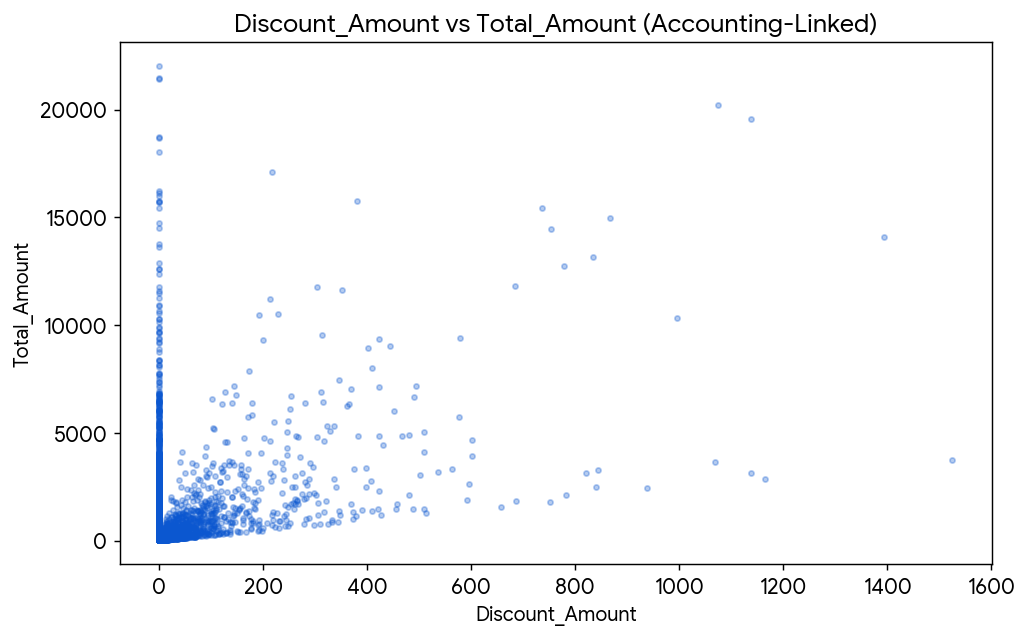

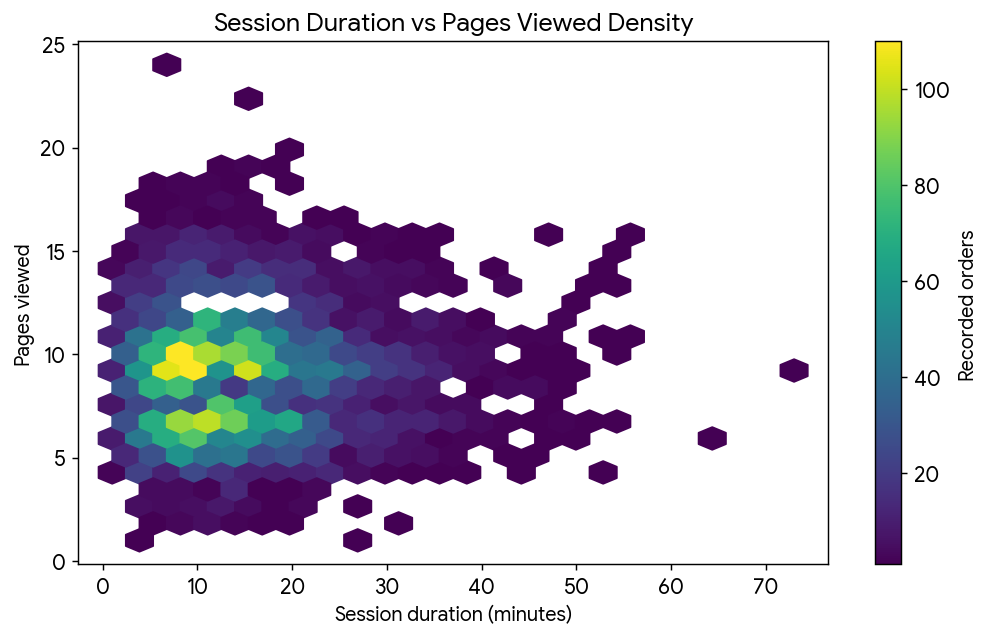

In [4]:
corr_matrix = df[NUMERIC].corr(method='spearman')
_ = save_table('09_spearman_matrix', corr_matrix.reset_index(names='variable'), 'Spearman correlation matrix.', show=False)

rows = []
for i, a in enumerate(NUMERIC):
    for b in NUMERIC[i+1:]:
        rho, p = stats.spearmanr(df[a], df[b])
        accounting = 'Total_Amount' in (a, b) and ({a, b} - {'Total_Amount'}).pop() in ['Unit_Price', 'Quantity', 'Discount_Amount']
        rows.append({
            'variable_a': a, 'variable_b': b, 'rho': rho, 'abs_rho': abs(rho),
            'p_value': np.nan if accounting else p, 'q_bh': np.nan, 'accounting_linked': accounting
        })
spearman_pairs = pd.DataFrame(rows)
mask = ~spearman_pairs.accounting_linked
spearman_pairs.loc[mask, 'q_bh'] = bh_q(spearman_pairs.loc[mask, 'p_value'])
spearman_pairs = spearman_pairs.sort_values('abs_rho', ascending=False).reset_index(drop=True)
spearman_pairs = save_table('10_spearman_pairs', spearman_pairs, 'Pairwise Spearman correlations with BH-FDR adjustment.')

selected = [
    ('Unit_Price', 'Total_Amount'), ('Quantity', 'Total_Amount'),
    ('Unit_Price', 'Discount_Amount'), ('Session_Duration_Minutes', 'Pages_Viewed'),
    ('Delivery_Time_Days', 'Customer_Rating')
]
rng = np.random.default_rng(SEED)
ci_rows = []
for a, b in selected:
    x, y = df[a].to_numpy(), df[b].to_numpy()
    draws = [stats.spearmanr(x[idx := rng.integers(0, len(df), len(df))], y[idx]).statistic for _ in range(1000)]
    lo, hi = np.quantile(draws, [.025, .975])
    ci_rows.append({'variable_a': a, 'variable_b': b, 'rho': stats.spearmanr(x, y).statistic, 'ci_low': lo, 'ci_high': hi})
spearman_ci = save_table('11_spearman_selected_ci', pd.DataFrame(ci_rows), '95% bootstrap confidence intervals for selected pairs.')

short = ['Age', 'Unit price', 'Quantity', 'Discount', 'Net amount', 'Session min', 'Pages', 'Delivery days', 'Rating']
plt.figure(figsize=(9.5, 7.5))
im = plt.imshow(corr_matrix, vmin=-1, vmax=1)
plt.colorbar(im, label='Spearman rho')
plt.xticks(range(len(NUMERIC)), short, rotation=45, ha='right')
plt.yticks(range(len(NUMERIC)), short)
for i in range(len(NUMERIC)):
    for j in range(len(NUMERIC)):
        plt.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.title('Spearman Rank Correlation Heatmap')
save_figure('07_spearman_heatmap', 'Spearman correlation heatmap.')

for a, b in [('Unit_Price', 'Total_Amount'), ('Discount_Amount', 'Total_Amount')]:
    plt.figure(figsize=(8, 5))
    plt.scatter(df[a], df[b], s=8, alpha=.3)
    plt.xlabel(a)
    plt.ylabel(b)
    plt.title(f'{a} vs {b} (Accounting-Linked)')
    save_figure(f'08_scatter_{a}', f'Scatterplot of {a} vs {b}.')

plt.figure(figsize=(8, 5))
plt.hexbin(df.Session_Duration_Minutes, df.Pages_Viewed, gridsize=25, mincnt=1)
plt.colorbar(label='Recorded orders')
plt.xlabel('Session duration (minutes)')
plt.ylabel('Pages viewed')
plt.title('Session Duration vs Pages Viewed Density')
save_figure('09_session_pages', 'Hexbin density of session duration vs pages viewed.')

## 5. Group Comparisons (Welch's t-test, Bootstrap, and Mann-Whitney U)

**12_primary_group_comparisons** — Welch t-tests, Hedges g, and 95% bootstrap CIs.

,comparison,outcome,n_positive,n_reference,mean_positive,mean_reference,median_positive,median_reference,mean_difference,welch_t,p_value,hedges_g,bootstrap_ci_low,bootstrap_ci_high,date_cluster_ci_low,date_cluster_ci_high,q_bh
0,Returning flag,Total_Amount,2990,2010,985.960147,978.867527,348.710,326.710,7.092620,0.127110,0.898860,0.003734,-100.531056,113.534331,-104.209479,115.777228,0.958264
1,Returning flag,Session_Duration_Minutes,2990,2010,14.455853,14.748259,13.000,13.000,-0.292406,-1.166669,0.243409,-0.033739,-0.773453,0.186794,-0.808482,0.219065,0.958264
2,Discount status,Total_Amount,1526,3474,980.964495,984.050878,302.735,351.025,-3.086383,-0.052337,0.958264,-0.001625,-116.171929,114.313026,-108.828107,116.673753,0.958264
3,Discount status,Quantity,1526,3474,2.229358,2.215889,2.000,2.000,0.013468,0.313521,0.753907,0.009627,-0.069975,0.095732,-0.068241,0.096977,0.958264


**13_group_rank_sensitivity** — Mann-Whitney U rank sensitivity tests.

,comparison,outcome,u,p_value,rank_biserial,q_bh
0,Returning flag,Total_Amount,3077868.5,0.145113,0.024266,0.145113
1,Discount status,Total_Amount,2561485.5,0.057799,-0.033643,0.115597


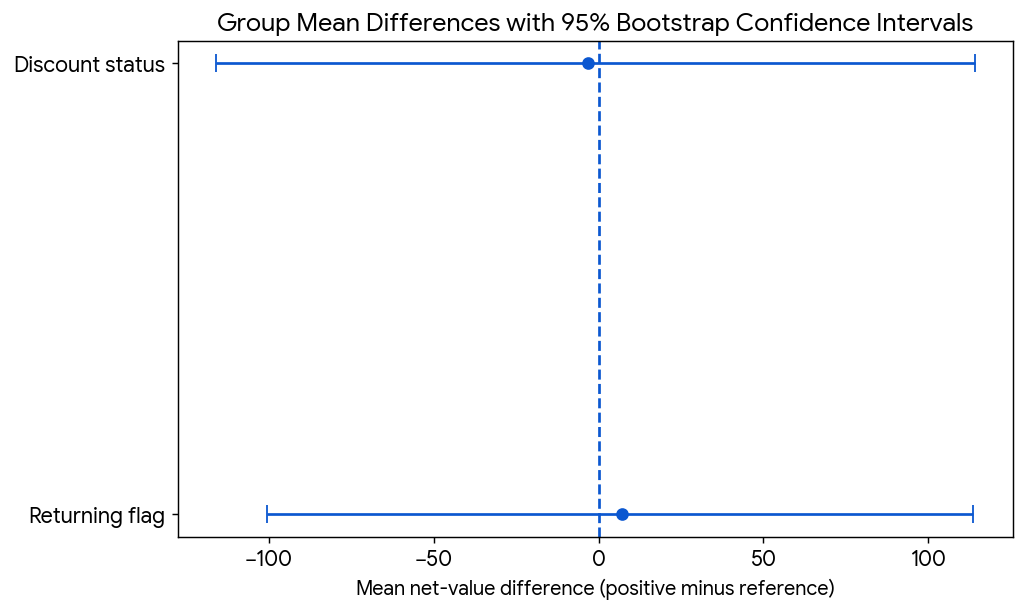

In [5]:
comparison_specs = [
    ('Returning flag', 'Is_Returning_Customer', 'Total_Amount'),
    ('Returning flag', 'Is_Returning_Customer', 'Session_Duration_Minutes'),
    ('Discount status', 'Discounted', 'Total_Amount'),
    ('Discount status', 'Discounted', 'Quantity')
]
comparison_rows, sensitivity_rows = [], []

for j, (label, group, outcome) in enumerate(comparison_specs):
    a = work.loc[work[group], outcome].to_numpy(float)
    b = work.loc[~work[group], outcome].to_numpy(float)
    test = stats.ttest_ind(a, b, equal_var=False)
    diff = a.mean() - b.mean()
    var_a, var_b = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    dof = (var_a + var_b)**2 / (var_a**2 / (len(a) - 1) + var_b**2 / (len(b) - 1))
    half = stats.t.ppf(.975, dof) * np.sqrt(var_a + var_b)
    pooled = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    g = (1 - 3 / (4 * (len(a) + len(b)) - 9)) * diff / pooled
    bootlo, boothi = bootstrap_difference(a, b, seed=SEED + j)

    daily = work.assign(_positive=work[group].astype(int)).groupby(['Date', '_positive'])[outcome].agg(['sum', 'count']).unstack(fill_value=0)
    sums0, sums1 = daily['sum'][0].to_numpy(), daily['sum'][1].to_numpy()
    counts0, counts1 = daily['count'][0].to_numpy(), daily['count'][1].to_numpy()
    rng = np.random.default_rng(SEED + 100 + j)
    cluster_draws = [sums1[ix := rng.integers(0, len(daily), len(daily))].sum() / counts1[ix].sum() - sums0[ix].sum() / counts0[ix].sum() for _ in range(2000)]
    daylo, dayhi = np.quantile(cluster_draws, [.025, .975])

    comparison_rows.append({
        'comparison': label, 'outcome': outcome, 'n_positive': len(a), 'n_reference': len(b),
        'mean_positive': a.mean(), 'mean_reference': b.mean(), 'median_positive': np.median(a), 'median_reference': np.median(b),
        'mean_difference': diff, 'welch_t': test.statistic, 'p_value': test.pvalue,
        'hedges_g': g, 'bootstrap_ci_low': bootlo, 'bootstrap_ci_high': boothi,
        'date_cluster_ci_low': daylo, 'date_cluster_ci_high': dayhi
    })
    if outcome == 'Total_Amount':
        mw = stats.mannwhitneyu(a, b, alternative='two-sided', method='asymptotic')
        sensitivity_rows.append({'comparison': label, 'outcome': outcome, 'u': mw.statistic, 'p_value': mw.pvalue, 'rank_biserial': 2 * mw.statistic / (len(a) * len(b)) - 1})

group_tests = pd.DataFrame(comparison_rows)
group_tests['q_bh'] = bh_q(group_tests.p_value)
group_tests = save_table('12_primary_group_comparisons', group_tests, 'Welch t-tests, Hedges g, and 95% bootstrap CIs.')

group_sensitivity = pd.DataFrame(sensitivity_rows)
group_sensitivity['q_bh'] = bh_q(group_sensitivity.p_value)
group_sensitivity = save_table('13_group_rank_sensitivity', group_sensitivity, 'Mann-Whitney U rank sensitivity tests.')

plot = group_tests.query('outcome == "Total_Amount"')
plt.figure(figsize=(8, 4.8))
plt.errorbar(plot.mean_difference, plot.comparison, xerr=[plot.mean_difference - plot.bootstrap_ci_low, plot.bootstrap_ci_high - plot.mean_difference], fmt='o', capsize=5)
plt.axvline(0, linestyle='--')
plt.xlabel('Mean net-value difference (positive minus reference)')
plt.title('Group Mean Differences with 95% Bootstrap Confidence Intervals')
save_figure('10_group_mean_differences', 'Mean difference confidence intervals for Total_Amount.')

## 6. Categorical Association Tests (Chi-Square and Bias-Corrected Cramér's V)

**14_categorical_tests** — Chi-square and bias-corrected Cramers V tests.

,variable_a,variable_b,chi_square,dof,p_value,cramers_v_bias_corrected,cramers_v_uncorrected,min_expected,assumption_check,q_bh
0,Device_Type,Is_Returning_Customer,5.885143,2,0.052730,0.027877,0.034308,198.5880,PASS,0.389502
1,Device_Type,Payment_Method,13.820854,8,0.086556,0.024128,0.037176,24.5024,PASS,0.389502
2,City,Product_Category,74.587573,63,0.150658,0.018198,0.046164,25.6200,PASS,0.451973
3,City,Is_Returning_Customer,9.922304,9,0.356812,0.013570,0.044547,84.4200,PASS,0.642261
4,Product_Category,Payment_Method,30.850765,28,0.323747,0.011932,0.039275,30.2560,PASS,0.642261
5,Gender,Is_Returning_Customer,0.125176,2,0.939331,0.000000,0.005004,29.3460,PASS,0.939331
6,Product_Category,Is_Returning_Customer,2.698880,7,0.911392,0.000000,0.023233,245.2200,PASS,0.939331
7,Payment_Method,Is_Returning_Customer,2.255308,4,0.688917,0.000000,0.021238,99.6960,PASS,0.885751
8,Product_Category,Device_Type,11.287856,14,0.663289,0.000000,0.033597,60.2680,PASS,0.885751


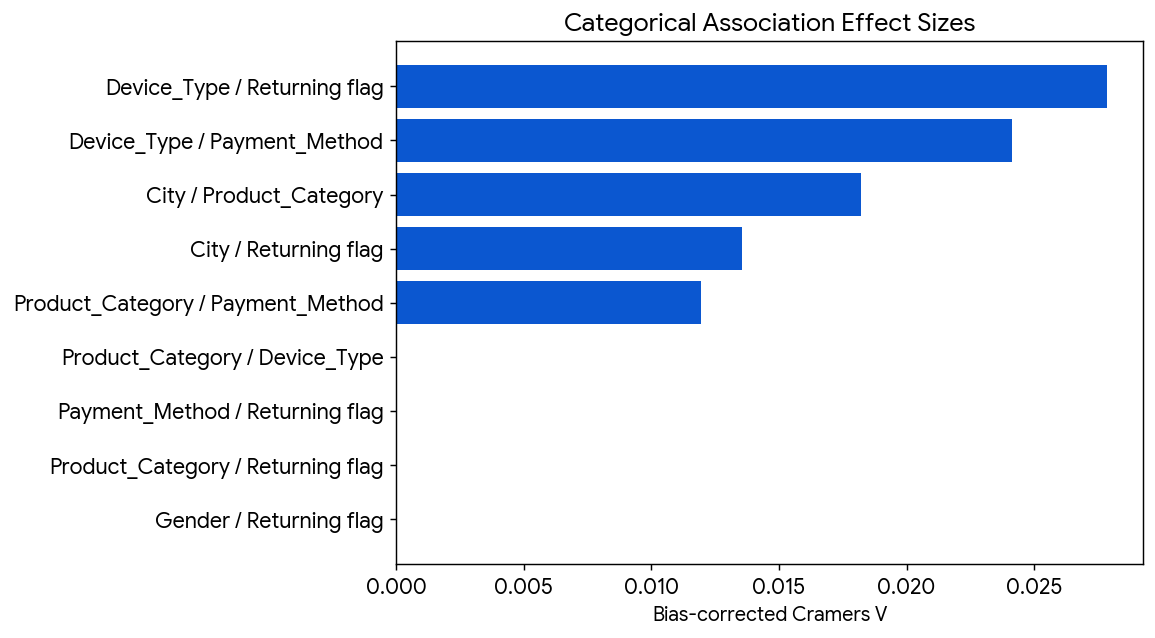

In [6]:
relationships = [
    ('Gender', 'Is_Returning_Customer'), ('City', 'Is_Returning_Customer'),
    ('Product_Category', 'Is_Returning_Customer'), ('Payment_Method', 'Is_Returning_Customer'),
    ('Device_Type', 'Is_Returning_Customer'), ('Product_Category', 'Payment_Method'),
    ('Product_Category', 'Device_Type'), ('City', 'Product_Category'),
    ('Device_Type', 'Payment_Method')
]

def corrected_cramers_v(counts):
    counts = np.asarray(counts, float)
    n = counts.sum()
    r, k = counts.shape
    chi2, p, dof, expected = stats.chi2_contingency(counts, correction=False)
    phi = chi2 / n
    correction = max(0, phi - (k - 1) * (r - 1) / (n - 1))
    denom = min(k - 1 - (k - 1)**2 / (n - 1), r - 1 - (r - 1)**2 / (n - 1))
    return float(np.sqrt(correction / denom)), float(np.sqrt(phi / min(r - 1, k - 1))), chi2, p, dof, expected

cat_rows = []
for a, b in relationships:
    cross = pd.crosstab(df[a], df[b])
    v, rawv, chi, p, dof, expected = corrected_cramers_v(cross)
    cat_rows.append({
        'variable_a': a, 'variable_b': b, 'chi_square': chi, 'dof': dof, 'p_value': p,
        'cramers_v_bias_corrected': v, 'cramers_v_uncorrected': rawv,
        'min_expected': expected.min(), 'assumption_check': 'PASS' if expected.min() >= 5 else 'REVIEW'
    })
cat_tests = pd.DataFrame(cat_rows)
cat_tests['q_bh'] = bh_q(cat_tests.p_value)
cat_tests = save_table('14_categorical_tests', cat_tests.sort_values('cramers_v_bias_corrected', ascending=False), 'Chi-square and bias-corrected Cramers V tests.')

plt.figure(figsize=(9, 5))
p = cat_tests.sort_values('cramers_v_bias_corrected')
labels = [a.replace('Is_Returning_Customer', 'Returning flag') + ' / ' + b.replace('Is_Returning_Customer', 'Returning flag') for a, b in zip(p.variable_a, p.variable_b)]
plt.barh(labels, p.cramers_v_bias_corrected)
plt.xlabel('Bias-corrected Cramers V')
plt.title('Categorical Association Effect Sizes')
save_figure('11_categorical_effect_sizes', 'Bias-corrected Cramers V across categorical pairs.')

## 7. Predictive Modeling: Delivery Duration Regression and Returning Flag Classification

**15_model_cv_summary** — 5-fold development cross-validation summary.

,task,model,metric,mean_across_folds,sd_across_folds
0,Delivery,OLS,MAE,2.706065,0.114647
1,Delivery,OLS,RMSE,3.474655,0.126417
2,Delivery,OLS,R2,-0.007666,0.008885
3,Delivery,Training mean,MAE,2.704317,0.104215
4,Delivery,Training mean,RMSE,3.466008,0.123473
5,Delivery,Training mean,R2,-0.002668,0.001970
6,Delivery,Training median,MAE,2.622197,0.122568
7,Delivery,Training median,RMSE,3.499985,0.142377
8,Delivery,Training median,R2,-0.022170,0.012722
9,Supplied flag,Logistic C=1,ROC_AUC,0.506469,0.012930


**16_model_holdout_metrics** — Chronological holdout evaluation metrics.

,task,model,metric,value,n
0,Delivery,OLS,MAE,2.737086,1008
1,Delivery,OLS,RMSE,3.493172,1008
2,Delivery,OLS,R2,-0.020111,1008
3,Delivery,Training mean,MAE,2.724549,1008
4,Delivery,Training mean,RMSE,3.458675,1008
5,Delivery,Training mean,R2,-0.000062,1008
6,Delivery,Training median,MAE,2.655754,1008
7,Delivery,Training median,RMSE,3.491060,1008
8,Delivery,Training median,R2,-0.018878,1008
9,Supplied flag,Logistic C=1,ROC_AUC,0.486171,1008


**17_model_holdout_uncertainty** — 95% bootstrap confidence intervals for holdout metrics.

,task,metric,ci_low,ci_high
0,Delivery,MAE,2.605768,2.873787
1,Delivery,RMSE,3.291939,3.695007
2,Delivery,R2,-0.035572,-0.008331
3,Delivery,MAE difference vs training median,0.042651,0.120481
4,Supplied flag,ROC_AUC,0.451190,0.523475
5,Supplied flag,Average_precision,0.578866,0.637680
6,Supplied flag,Brier_score,0.238545,0.243094
7,Supplied flag,Brier difference vs training prevalence,-0.000291,0.004258


**19_flag_confusion_matrices** — Holdout confusion matrices at threshold 0.5.

,model,actual,predicted,count
0,Logistic C=1,0,0,2
1,Logistic C=1,0,1,395
2,Logistic C=1,1,0,1
3,Logistic C=1,1,1,610
4,Training prevalence,0,0,0
5,Training prevalence,0,1,397
6,Training prevalence,1,0,0
7,Training prevalence,1,1,611


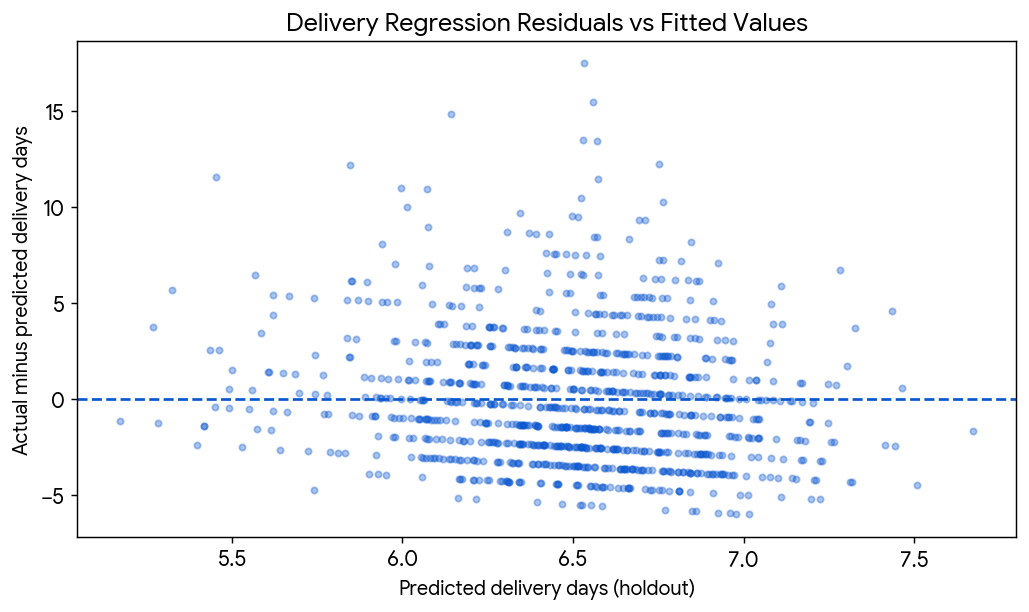

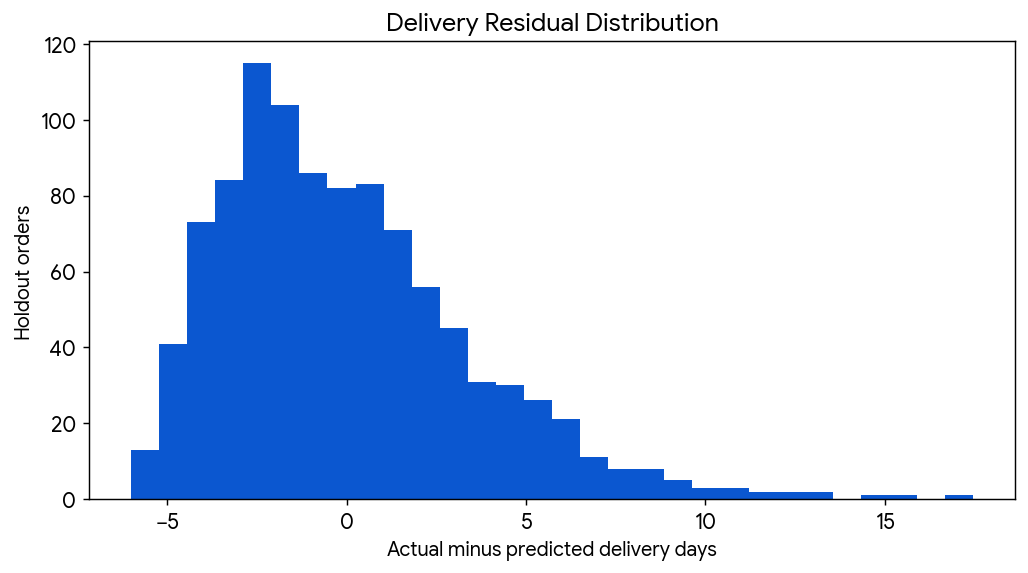

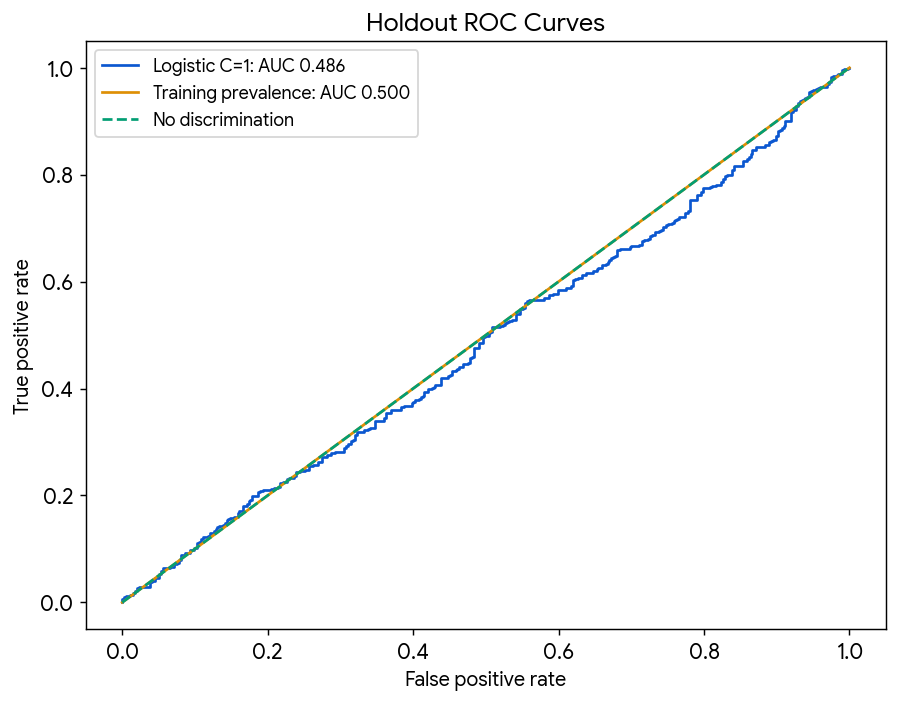

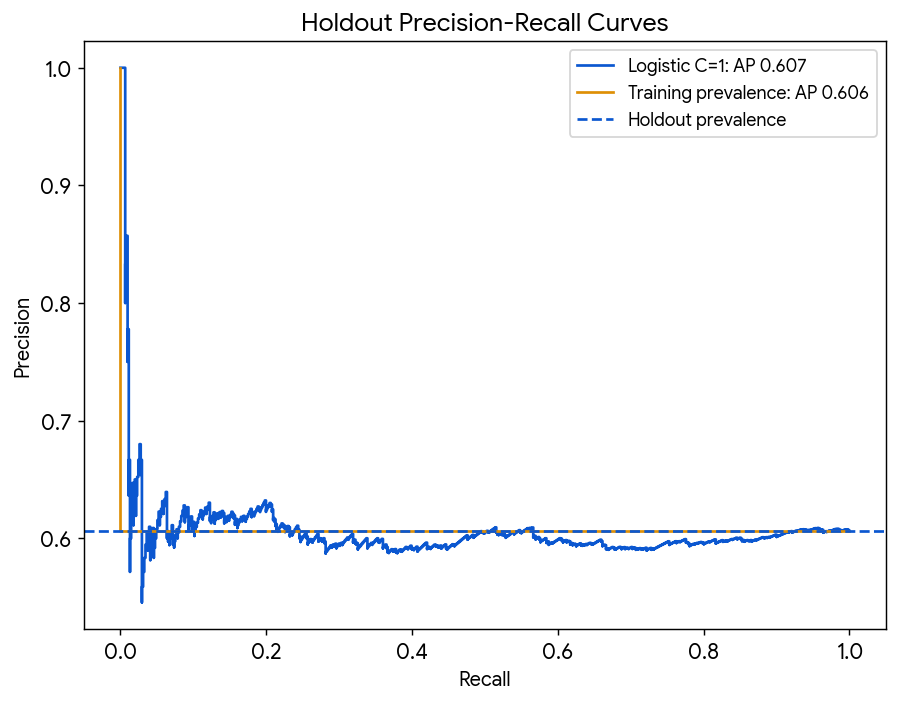

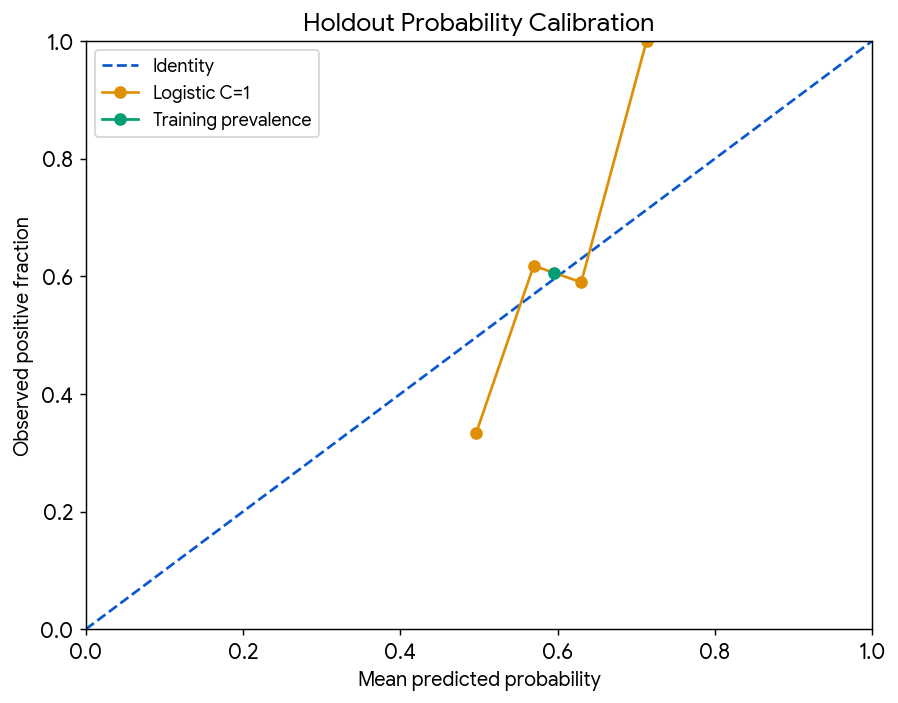

In [7]:
model_numeric = ['Age', 'Unit_Price', 'Quantity', 'Discount_Amount', 'Session_Duration_Minutes', 'Pages_Viewed']
model_categorical = ['Gender', 'City', 'Product_Category', 'Payment_Method', 'Device_Type']
model_features = model_numeric + model_categorical

cutoff = pd.Timestamp(sorted(df.Date.unique())[int(.8 * df.Date.nunique())])
dev_index = np.flatnonzero(df.Date.lt(cutoff).to_numpy())
test_index = np.flatnonzero(df.Date.ge(cutoff).to_numpy())

Xdev, Xtest = df.iloc[dev_index][model_features], df.iloc[test_index][model_features]
yregdev, yregtest = df.iloc[dev_index].Delivery_Time_Days, df.iloc[test_index].Delivery_Time_Days
yclfdev, yclftest = df.iloc[dev_index].Is_Returning_Customer.astype(int), df.iloc[test_index].Is_Returning_Customer.astype(int)

preprocess = ColumnTransformer([
    ('numeric', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), model_numeric),
    ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('encode', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))]), model_categorical)
])

regressors = {
    'OLS': Pipeline([('preprocess', clone(preprocess)), ('model', LinearRegression())]),
    'Training mean': DummyRegressor(strategy='mean'),
    'Training median': DummyRegressor(strategy='median')
}
classifiers = {
    'Logistic C=1': Pipeline([('preprocess', clone(preprocess)), ('model', LogisticRegression(C=1, max_iter=3000, class_weight=None, random_state=SEED))]),
    'Training prevalence': DummyClassifier(strategy='prior')
}

def regression_metrics(y, p):
    return {'MAE': mean_absolute_error(y, p), 'RMSE': mean_squared_error(y, p)**.5, 'R2': r2_score(y, p)}

def classification_metrics(y, p):
    pred = (np.asarray(p) >= .5).astype(int)
    precision, recall, _ = precision_recall_curve(y, p)
    return {
        'ROC_AUC': roc_auc_score(y, p), 'Average_precision': average_precision_score(y, p),
        'PR_AUC_trapezoid': auc(recall, precision), 'Accuracy': accuracy_score(y, pred),
        'Balanced_accuracy': balanced_accuracy_score(y, pred), 'Precision': precision_score(y, pred, zero_division=0),
        'Recall': recall_score(y, pred, zero_division=0), 'F1': f1_score(y, pred, zero_division=0),
        'Brier_score': brier_score_loss(y, p), 'Log_loss': log_loss(y, p, labels=[0, 1])
    }

cv_rows = []
for task, models, target, splitter, metric_fn in [
    ('Delivery', regressors, yregdev, KFold(n_splits=5, shuffle=True, random_state=SEED), regression_metrics),
    ('Supplied flag', classifiers, yclfdev, StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED), classification_metrics)
]:
    for fold, (tr, va) in enumerate(splitter.split(Xdev, target), start=1):
        for name, est in models.items():
            fitted = checked_fit(clone(est), Xdev.iloc[tr], target.iloc[tr], f'{task} {name} CV fold {fold}')
            p = fitted.predict(Xdev.iloc[va]) if task == 'Delivery' else fitted.predict_proba(Xdev.iloc[va])[:, 1]
            for metric, value in metric_fn(target.iloc[va], p).items():
                cv_rows.append({'task': task, 'model': name, 'fold': fold, 'metric': metric, 'value': value})

cv_summary = pd.DataFrame(cv_rows).groupby(['task', 'model', 'metric'], sort=False).value.agg(['mean', 'std']).reset_index().rename(columns={'mean': 'mean_across_folds', 'std': 'sd_across_folds'})
cv_summary = save_table('15_model_cv_summary', cv_summary, '5-fold development cross-validation summary.')

holdout_rows, fitted_reg, fitted_clf, reg_predictions, clf_predictions = [], {}, {}, {}, {}
for task, models, yd, yt, metric_fn in [
    ('Delivery', regressors, yregdev, yregtest, regression_metrics),
    ('Supplied flag', classifiers, yclfdev, yclftest, classification_metrics)
]:
    for name, est in models.items():
        fitted = checked_fit(clone(est), Xdev, yd, f'{task} {name} final fit')
        p = fitted.predict(Xtest) if task == 'Delivery' else fitted.predict_proba(Xtest)[:, 1]
        if task == 'Delivery':
            fitted_reg[name] = fitted
            reg_predictions[name] = p
        else:
            fitted_clf[name] = fitted
            clf_predictions[name] = p
        for metric, value in metric_fn(yt, p).items():
            holdout_rows.append({'task': task, 'model': name, 'metric': metric, 'value': value, 'n': len(yt)})

holdout_metrics = save_table('16_model_holdout_metrics', pd.DataFrame(holdout_rows), 'Chronological holdout evaluation metrics.')

rng = np.random.default_rng(SEED)
reg_draw, clf_draw = [], []
yr, yc = yregtest.to_numpy(), yclftest.to_numpy()
pos, neg = np.flatnonzero(yc == 1), np.flatnonzero(yc == 0)
for _ in range(MODEL_BOOTSTRAPS):
    ix = rng.integers(0, len(yr), len(yr))
    p, a = reg_predictions['OLS'][ix], yr[ix]
    reg_draw.append([mean_absolute_error(a, p), mean_squared_error(a, p)**.5, r2_score(a, p), mean_absolute_error(a, p) - mean_absolute_error(a, reg_predictions['Training median'][ix])])
    jx = np.r_[rng.choice(pos, len(pos), replace=True), rng.choice(neg, len(neg), replace=True)]
    b, p, base = yc[jx], clf_predictions['Logistic C=1'][jx], clf_predictions['Training prevalence'][jx]
    clf_draw.append([roc_auc_score(b, p), average_precision_score(b, p), brier_score_loss(b, p), brier_score_loss(b, p) - brier_score_loss(b, base)])

ci_rows = []
for task, labels, draws in [
    ('Delivery', ['MAE', 'RMSE', 'R2', 'MAE difference vs training median'], np.array(reg_draw)),
    ('Supplied flag', ['ROC_AUC', 'Average_precision', 'Brier_score', 'Brier difference vs training prevalence'], np.array(clf_draw))
]:
    for j, metric in enumerate(labels):
        lo, hi = np.quantile(draws[:, j], [.025, .975])
        ci_rows.append({'task': task, 'metric': metric, 'ci_low': lo, 'ci_high': hi})
model_ci = save_table('17_model_holdout_uncertainty', pd.DataFrame(ci_rows), '95% bootstrap confidence intervals for holdout metrics.')

Xdesign = fitted_reg['OLS'].named_steps['preprocess'].transform(Xdev)
feature_names = fitted_reg['OLS'].named_steps['preprocess'].get_feature_names_out()
ols = sm.OLS(yregdev.to_numpy(), sm.add_constant(Xdesign)).fit(cov_type='HC3')
coef = pd.DataFrame({'term': ['Intercept'] + list(feature_names), 'coefficient': ols.params, 'robust_se': ols.bse, 'p_value': ols.pvalues})
coef['q_bh'] = np.nan
coef.loc[coef.term != 'Intercept', 'q_bh'] = bh_q(coef.loc[coef.term != 'Intercept', 'p_value'])
coefficients = save_table('18_delivery_coefficients_hc3', coef, 'HC3-robust OLS regression coefficients.', show=False)

conf_rows, cal_rows = [], []
for name, p in clf_predictions.items():
    cm = confusion_matrix(yclftest, (p >= .5).astype(int), labels=[0, 1])
    for actual in range(2):
        for predicted in range(2):
            conf_rows.append({'model': name, 'actual': actual, 'predicted': predicted, 'count': int(cm[actual, predicted])})
    cal = pd.DataFrame({'actual': yclftest.to_numpy(), 'p': p})
    cal['bin'] = pd.cut(cal.p, bins=np.linspace(0, 1, 11), include_lowest=True)
    for b, g in cal.groupby('bin', observed=True):
        cal_rows.append({'model': name, 'probability_bin': str(b), 'n': len(g), 'mean_prediction': g.p.mean(), 'observed_fraction': g.actual.mean()})
confusion = save_table('19_flag_confusion_matrices', pd.DataFrame(conf_rows), 'Holdout confusion matrices at threshold 0.5.')
calibration = save_table('20_flag_calibration', pd.DataFrame(cal_rows), 'Calibration bins on holdout set.', show=False)

reg_resid = yr - reg_predictions['OLS']
plt.figure(figsize=(8, 4.8))
plt.scatter(reg_predictions['OLS'], reg_resid, s=12, alpha=.35)
plt.axhline(0, linestyle='--')
plt.xlabel('Predicted delivery days (holdout)')
plt.ylabel('Actual minus predicted delivery days')
plt.title('Delivery Regression Residuals vs Fitted Values')
save_figure('12_delivery_residuals', 'OLS holdout residuals.')

plt.figure(figsize=(8, 4.5))
plt.hist(reg_resid, bins=30)
plt.xlabel('Actual minus predicted delivery days')
plt.ylabel('Holdout orders')
plt.title('Delivery Residual Distribution')
save_figure('13_delivery_residual_distribution', 'Distribution of OLS holdout residuals.')

plt.figure(figsize=(7, 5.5))
for name, p in clf_predictions.items():
    fpr, tpr, _ = roc_curve(yclftest, p)
    plt.plot(fpr, tpr, label=f'{name}: AUC {roc_auc_score(yclftest, p):.3f}')
plt.plot([0, 1], [0, 1], linestyle='--', label='No discrimination')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('Holdout ROC Curves')
plt.legend()
save_figure('14_flag_roc', 'Holdout ROC curves.')

plt.figure(figsize=(7, 5.5))
for name, p in clf_predictions.items():
    precision, recall, _ = precision_recall_curve(yclftest, p)
    plt.step(recall, precision, where='post', label=f'{name}: AP {average_precision_score(yclftest, p):.3f}')
plt.axhline(yclftest.mean(), linestyle='--', label='Holdout prevalence')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Holdout Precision-Recall Curves')
plt.legend()
save_figure('15_flag_precision_recall', 'Holdout precision-recall curves.')

plt.figure(figsize=(7, 5.5))
plt.plot([0, 1], [0, 1], linestyle='--', label='Identity')
for name, g in calibration.groupby('model'):
    plt.plot(g.mean_prediction, g.observed_fraction, marker='o', label=name)
plt.xlabel('Mean predicted probability')
plt.ylabel('Observed positive fraction')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.title('Holdout Probability Calibration')
plt.legend()
save_figure('16_flag_calibration', 'Holdout reliability curve.')

## 8. Weekly Revenue Forecasting and Monte Carlo Simulation

**21_forecast_model_selection** — Rolling-origin development selection (MAE).

,model,MAE,scored_weeks,RMSE,selected_before_final_test
0,Training mean,16301.703264,32,21531.659607,True
1,ETS additive trend,17620.346751,32,22377.807816,False
2,Naive last week,24646.613750,32,31028.270043,False
3,Drift,26307.828495,32,33263.657243,False


**22_forecast_holdout_metrics** — Final 8-week holdout forecast evaluation.

,model,selected_before_test,n_weeks,MAE,RMSE,R2,WAPE,MASE
0,Training mean,True,8,17452.227500,24232.970313,-0.080560,0.212244,0.923326
1,Naive last week,False,8,18461.440000,26746.318032,-0.316326,0.224518,0.976719
2,Drift,False,8,18549.858182,26833.490112,-0.324921,0.225593,0.981397
3,ETS additive trend,False,8,18410.347281,23500.276581,-0.016205,0.223897,0.974016


**23_historical_projection** — 8-week historical projection from last complete week.

,week_end,model,projected_value,error_band_80_low,error_band_80_high
0,2024-03-31,Training mean,76437.417969,56501.228377,110195.896177
1,2024-04-07,Training mean,76437.417969,56501.228377,110195.896177
2,2024-04-14,Training mean,76437.417969,56501.228377,110195.896177
3,2024-04-21,Training mean,76437.417969,56501.228377,110195.896177
4,2024-04-28,Training mean,76437.417969,56501.228377,110195.896177
5,2024-05-05,Training mean,76437.417969,56501.228377,110195.896177
6,2024-05-12,Training mean,76437.417969,56501.228377,110195.896177
7,2024-05-19,Training mean,76437.417969,56501.228377,110195.896177


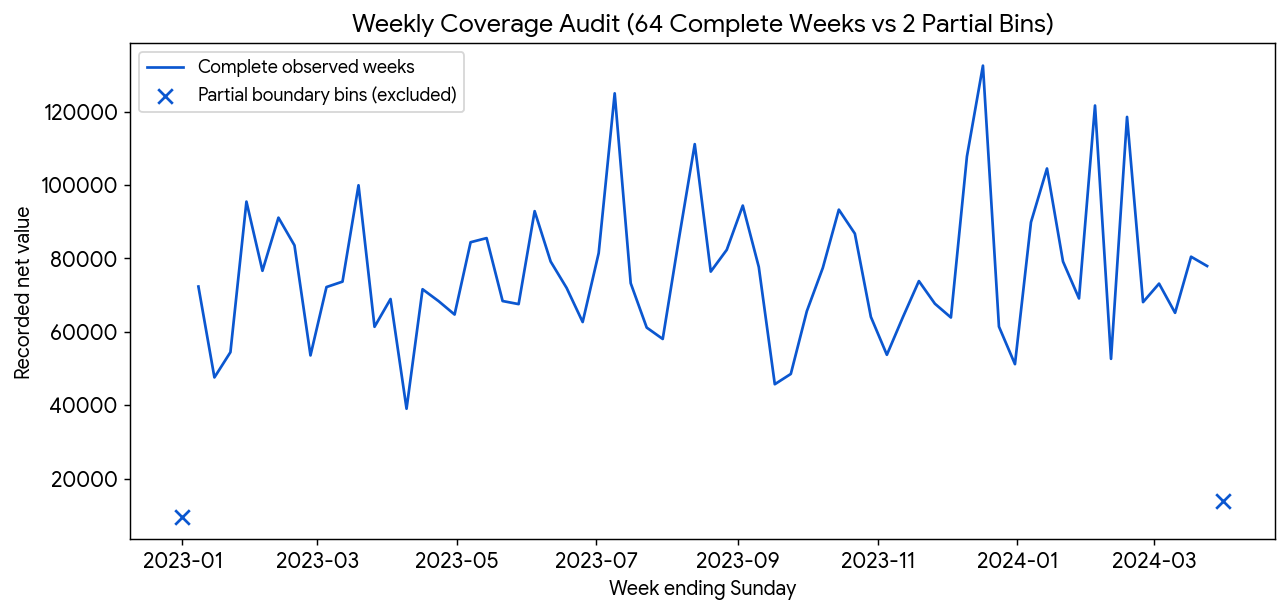

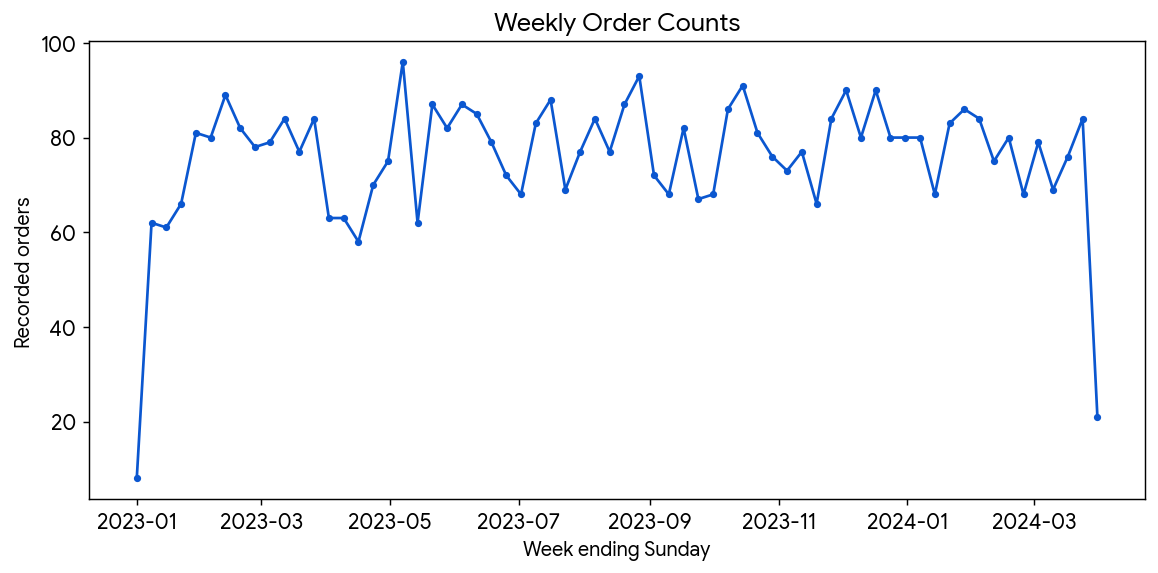

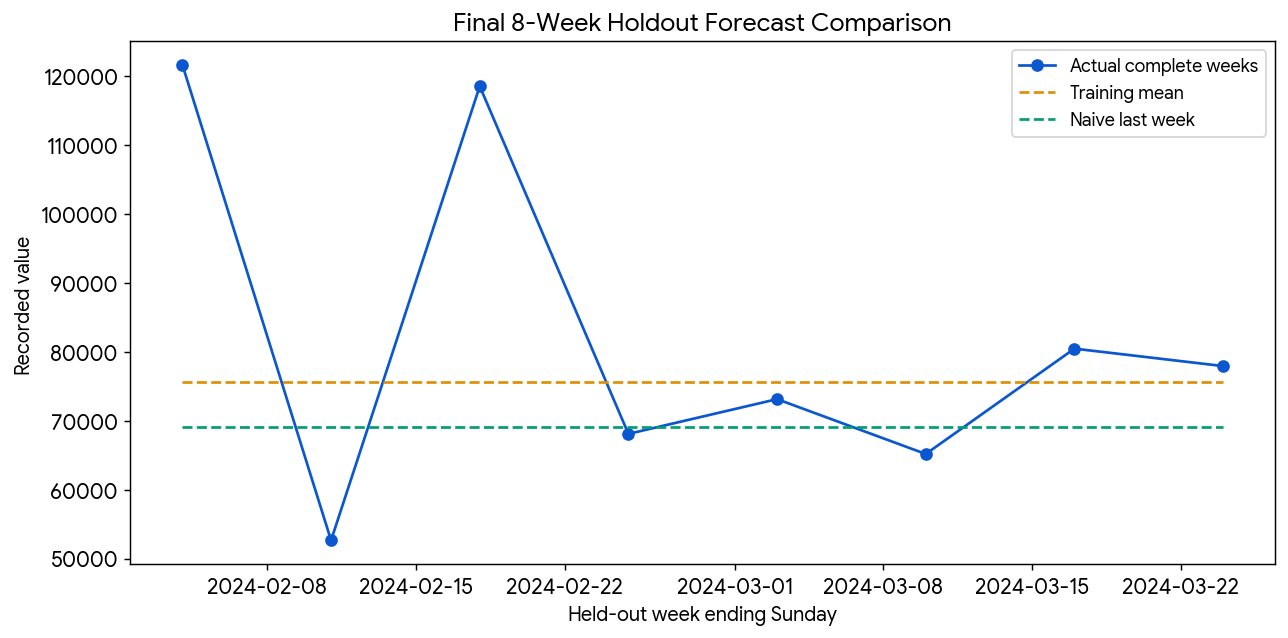

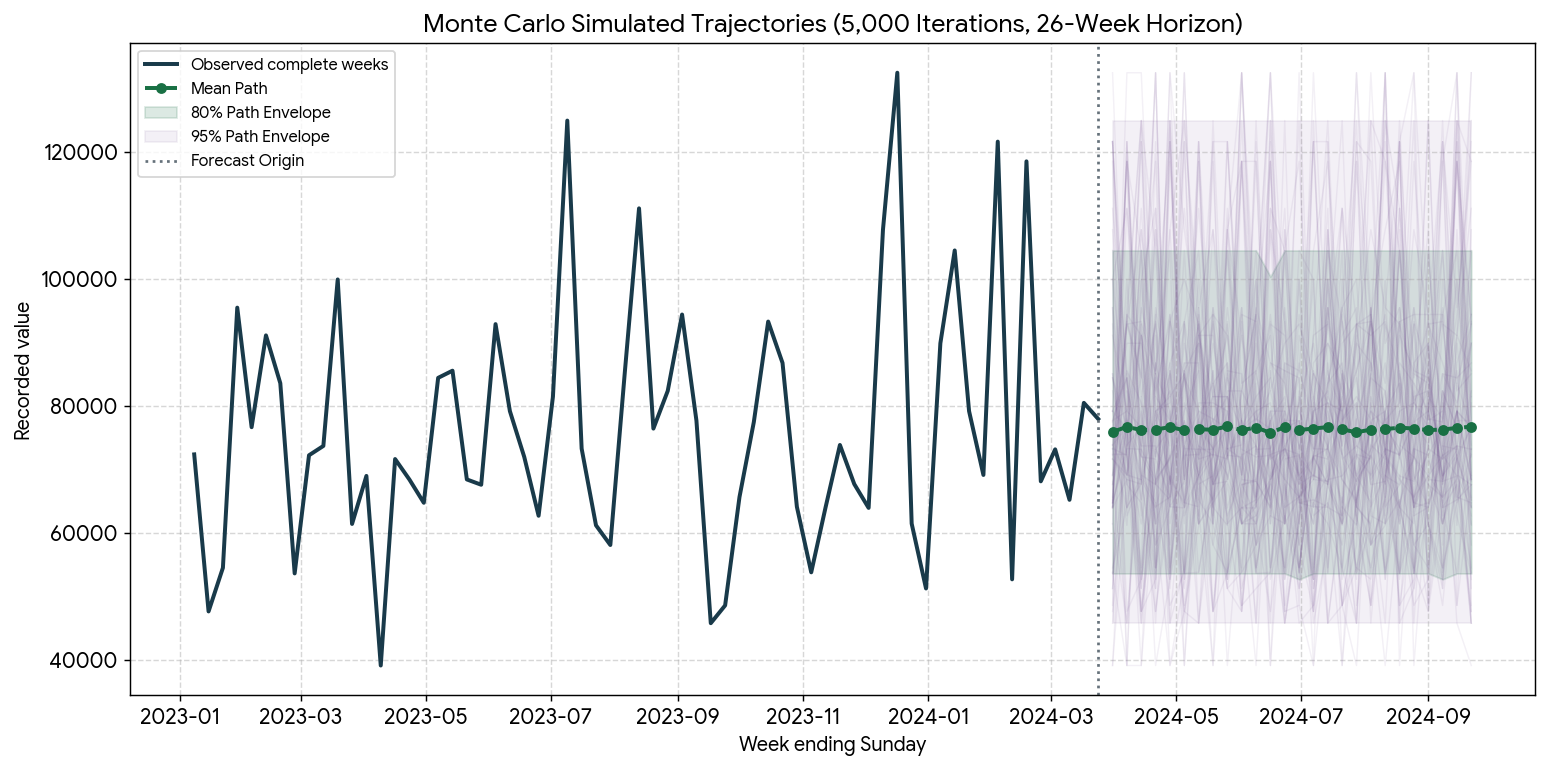

**24_outlier_removed_forecast_metrics** — Out-of-sample baseline forecast comparison with and without upper IQR outliers.

,Dataset,Training_Mean,MAE,RMSE,WAPE
0,Original (All Data),75610.329821,17452.2275,24232.970313,0.212244
1,Filtered (546 Upper Outliers Removed),33373.928214,5064.6550,6397.536207,0.160551


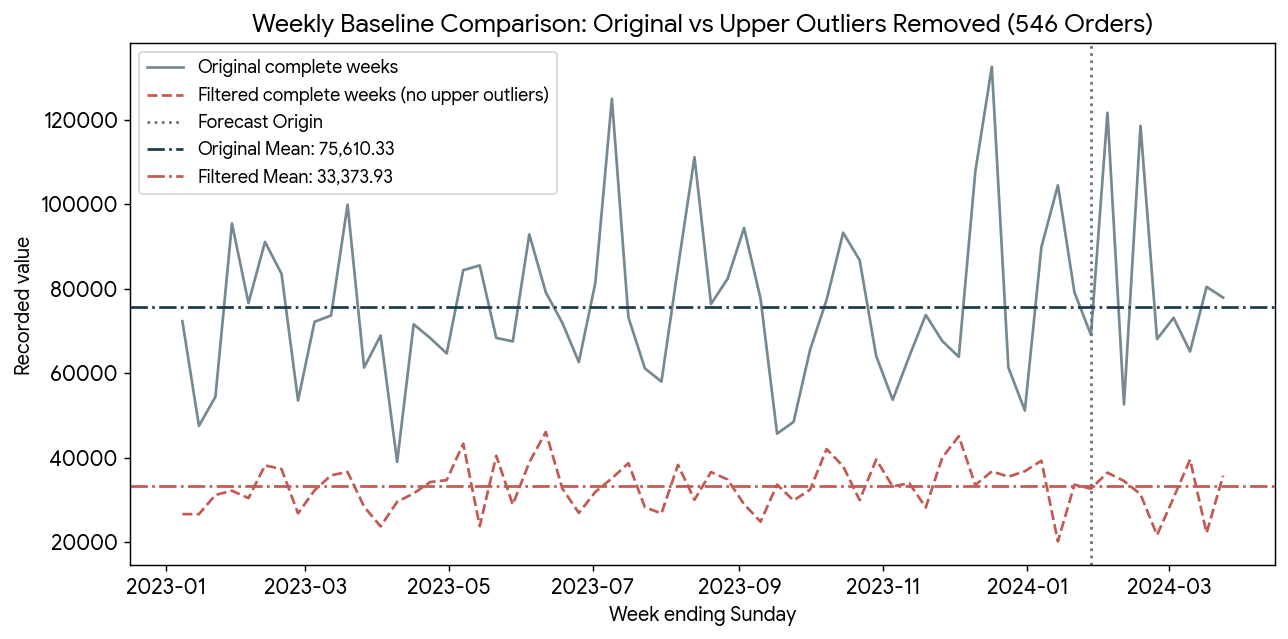

In [8]:
weekly = df.set_index('Date').resample('W-SUN').agg(
    total_value=('Total_Amount', 'sum'),
    orders=('Order_ID', 'size'),
    observed_days=('Order_ID', lambda x: x.index.nunique())
).reset_index().rename(columns={'Date': 'week_end'})
weekly['week_start'] = weekly.week_end - pd.Timedelta(days=6)
weekly['complete_within_file_window'] = (
    (weekly.week_start >= df.Date.min()) &
    (weekly.week_end <= df.Date.max()) &
    (weekly.observed_days == 7)
)

full = weekly.loc[weekly.complete_within_file_window].set_index('week_end')['total_value'].asfreq('W-SUN')
H = FORECAST_HORIZON
pretest = full.iloc[:-H]
test_weekly = full.iloc[-H:]

def forecast_model(name, train, h, context):
    a = np.asarray(train, float)
    if name == 'Training mean':
        return np.repeat(a.mean(), h)
    if name == 'Naive last week':
        return np.repeat(a[-1], h)
    if name == 'Drift':
        return a[-1] + (a[-1] - a[0]) / (len(a) - 1) * np.arange(1, h + 1)
    if name == 'ETS additive trend':
        scale = float(a.mean())
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            fit = ExponentialSmoothing(a / scale, trend='add', seasonal=None, initialization_method='estimated').fit(optimized=True)
        for w in caught:
            WARNING_LOG.append({'context': context, 'category': w.category.__name__, 'message': str(w.message)})
        return np.asarray(fit.forecast(h)) * scale
    raise ValueError(name)

forecast_names = ['Training mean', 'Naive last week', 'Drift', 'ETS additive trend']
origins = list(range(len(pretest) - 4 * H, len(pretest), H))

bt_rows = []
for origin in origins:
    train, valid = pretest.iloc[:origin], pretest.iloc[origin:origin + H]
    for name in forecast_names:
        pred = forecast_model(name, train, H, f'Forecast CV {train.index[-1].date()} {name}')
        for horizon, (date, actual, p) in enumerate(zip(valid.index, valid, pred), start=1):
            bt_rows.append({'model': name, 'week_end': date, 'actual': actual, 'prediction': p, 'error': actual - p, 'absolute_error': abs(actual - p), 'squared_error': (actual - p)**2})

backtest = pd.DataFrame(bt_rows)
selection = backtest.groupby('model', sort=False).agg(MAE=('absolute_error', 'mean'), MSE=('squared_error', 'mean'), scored_weeks=('actual', 'size')).reset_index()
selection['RMSE'] = np.sqrt(selection.MSE)
selection = selection.drop(columns='MSE').sort_values(['MAE', 'model']).reset_index(drop=True)
selected_forecast = str(selection.iloc[0].model)
selection['selected_before_final_test'] = selection.model.eq(selected_forecast)
forecast_selection = save_table('21_forecast_model_selection', selection, 'Rolling-origin development selection (MAE).')

forecast_test_rows, forecast_test_preds = [], []
scale_naive = np.mean(np.abs(np.diff(pretest)))
for name in forecast_names:
    p = forecast_model(name, pretest, H, f'Forecast holdout {name}')
    actual = test_weekly.to_numpy()
    err = actual - p
    forecast_test_rows.append({
        'model': name, 'selected_before_test': name == selected_forecast, 'n_weeks': H,
        'MAE': np.mean(abs(err)), 'RMSE': np.sqrt(np.mean(err**2)), 'R2': r2_score(actual, p),
        'WAPE': np.sum(abs(err)) / np.sum(abs(actual)), 'MASE': np.mean(abs(err)) / scale_naive
    })
    for h, (date, a, f) in enumerate(zip(test_weekly.index, actual, p), start=1):
        forecast_test_preds.append({'model': name, 'week_end': date, 'horizon': h, 'actual': a, 'prediction': f, 'error': a - f})

forecast_test = save_table('22_forecast_holdout_metrics', pd.DataFrame(forecast_test_rows), 'Final 8-week holdout forecast evaluation.')
forecast_test_predictions = pd.DataFrame(forecast_test_preds)

future = forecast_model(selected_forecast, full, H, 'Refit selected model')
future_dates = pd.date_range(full.index[-1] + pd.Timedelta(days=7), periods=H, freq='W-SUN')
errors = backtest.loc[backtest.model.eq(selected_forecast), 'error'].to_numpy()
errlo, errhi = np.quantile(errors, [.1, .9])
historical_projection = save_table('23_historical_projection', pd.DataFrame({
    'week_end': future_dates, 'model': selected_forecast, 'projected_value': future,
    'error_band_80_low': future + errlo, 'error_band_80_high': future + errhi
}), '8-week historical projection from last complete week.')

plt.figure(figsize=(10, 4.8))
plt.plot(full.index, full.values, label='Complete observed weeks')
plt.scatter(weekly.loc[~weekly.complete_within_file_window, 'week_end'], weekly.loc[~weekly.complete_within_file_window, 'total_value'], marker='x', s=65, label='Partial boundary bins (excluded)')
plt.xlabel('Week ending Sunday')
plt.ylabel('Recorded net value')
plt.title('Weekly Coverage Audit (64 Complete Weeks vs 2 Partial Bins)')
plt.legend()
save_figure('17_weekly_coverage', 'Complete weeks vs partial boundary bins.')

plt.figure(figsize=(9, 4.5))
plt.plot(weekly.week_end, weekly.orders, marker='o', markersize=3)
plt.xlabel('Week ending Sunday')
plt.ylabel('Recorded orders')
plt.title('Weekly Order Counts')
save_figure('18_weekly_orders', 'Weekly order count trajectory.')

plt.figure(figsize=(10, 5))
plt.plot(test_weekly.index, test_weekly.values, marker='o', label='Actual complete weeks')
for name in [selected_forecast] + [n for n in ['Training mean', 'Naive last week'] if n != selected_forecast]:
    p = forecast_test_predictions.query('model == @name')
    plt.plot(p.week_end, p.prediction, linestyle='--', label=name)
plt.xlabel('Held-out week ending Sunday')
plt.ylabel('Recorded value')
plt.title('Final 8-Week Holdout Forecast Comparison')
plt.legend()
save_figure('19_forecast_holdout', 'Holdout forecast comparison.')

EXTENDED_HORIZON = 26
N_SIMULATIONS = 5000
np.random.seed(SEED)
series_data = full.to_numpy()
historical_dates = full.index
mean_val = series_data.mean()
residuals = series_data - mean_val
base_forecast = np.repeat(mean_val, EXTENDED_HORIZON)

simulated_paths = np.zeros((N_SIMULATIONS, EXTENDED_HORIZON))
for i in range(N_SIMULATIONS):
    simulated_paths[i, :] = base_forecast + np.random.choice(residuals, size=EXTENDED_HORIZON, replace=True)

mean_path = np.mean(simulated_paths, axis=0)
lower_95, upper_95 = np.percentile(simulated_paths, [2.5, 97.5], axis=0)
lower_80, upper_80 = np.percentile(simulated_paths, [10, 90], axis=0)
future_dates_extended = pd.date_range(historical_dates[-1] + pd.Timedelta(days=7), periods=EXTENDED_HORIZON, freq='W-SUN')

plt.figure(figsize=(12, 6))
plt.plot(historical_dates, series_data, label='Observed complete weeks', color='#193A4A', linewidth=2.2)
for idx in np.random.choice(N_SIMULATIONS, size=75, replace=False):
    plt.plot(future_dates_extended, simulated_paths[idx, :], color='#6D488D', alpha=0.08, linewidth=0.8)
plt.plot(future_dates_extended, mean_path, linestyle='--', marker='o', label='Mean Path', color='#197044', linewidth=2.2, markersize=5)
plt.fill_between(future_dates_extended, lower_80, upper_80, alpha=0.15, color='#197044', label='80% Path Envelope')
plt.fill_between(future_dates_extended, lower_95, upper_95, alpha=0.08, color='#6D488D', label='95% Path Envelope')
plt.axvline(historical_dates[-1], linestyle=':', color='#65717A', label='Forecast Origin')
plt.xlabel('Week ending Sunday')
plt.ylabel('Recorded value')
plt.title(f'Monte Carlo Simulated Trajectories ({N_SIMULATIONS:,} Iterations, 26-Week Horizon)')
plt.legend(loc='upper left', fontsize=9)
plt.grid(True, linestyle='--', alpha=0.5)
save_figure('20_monte_carlo_pathing', '26-week Monte Carlo path simulation.')

q1, q3 = df['Total_Amount'].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
upper_outliers_mask = df['Total_Amount'] > upper_fence
df_filtered = df[~upper_outliers_mask].copy()

weekly_filtered = df_filtered.set_index('Date').resample('W-SUN').agg(
    total_value=('Total_Amount', 'sum'), observed_days=('Order_ID', lambda x: x.index.nunique())
).reset_index().rename(columns={'Date': 'week_end'})
weekly_filtered['week_start'] = weekly_filtered.week_end - pd.Timedelta(days=6)
weekly_filtered['complete_within_file_window'] = (
    (weekly_filtered.week_start >= df.Date.min()) &
    (weekly_filtered.week_end <= df.Date.max()) &
    (weekly_filtered.observed_days == 7)
)
full_filtered = weekly_filtered.loc[weekly_filtered.complete_within_file_window].set_index('week_end')['total_value'].asfreq('W-SUN')

train_orig, test_orig = full.iloc[:-H], full.iloc[-H:]
train_filt, test_filt = full_filtered.iloc[:-H], full_filtered.iloc[-H:]
mean_orig, mean_filt = train_orig.mean(), train_filt.mean()
pred_orig, pred_filt = np.repeat(mean_orig, H), np.repeat(mean_filt, H)

outlier_comp = save_table('24_outlier_removed_forecast_metrics', pd.DataFrame([
    {'Dataset': 'Original (All Data)', 'Training_Mean': mean_orig, 'MAE': mean_absolute_error(test_orig, pred_orig), 'RMSE': np.sqrt(mean_squared_error(test_orig, pred_orig)), 'WAPE': np.sum(np.abs(test_orig - pred_orig)) / np.sum(test_orig)},
    {'Dataset': f'Filtered ({int(upper_outliers_mask.sum())} Upper Outliers Removed)', 'Training_Mean': mean_filt, 'MAE': mean_absolute_error(test_filt, pred_filt), 'RMSE': np.sqrt(mean_squared_error(test_filt, pred_filt)), 'WAPE': np.sum(np.abs(test_filt - pred_filt)) / np.sum(test_filt)}
]), 'Out-of-sample baseline forecast comparison with and without upper IQR outliers.')

plt.figure(figsize=(10, 5))
plt.plot(full.index, full.values, label='Original complete weeks', color='#193A4A', alpha=0.6)
plt.plot(full_filtered.index, full_filtered.values, label='Filtered complete weeks (no upper outliers)', color='#C25953', linestyle='--')
plt.axvline(train_orig.index[-1], linestyle=':', color='#65717A', label='Forecast Origin')
plt.axhline(mean_orig, color='#193A4A', linestyle='-.', label=f'Original Mean: {mean_orig:,.2f}')
plt.axhline(mean_filt, color='#C25953', linestyle='-.', label=f'Filtered Mean: {mean_filt:,.2f}')
plt.title(f'Weekly Baseline Comparison: Original vs Upper Outliers Removed ({int(upper_outliers_mask.sum())} Orders)')
plt.xlabel('Week ending Sunday')
plt.ylabel('Recorded value')
plt.legend()
save_figure('21_outlier_removed_forecast', 'Weekly series before and after removing upper IQR outliers.')

## 9. Financial Simulation: Discount Removal and Net Income Impact

**25_no_discount_simulation** — Bootstrap simulation of recovered revenue under full gross pricing.

,Metric,Value
0,Observed Net Revenue,4.915545e+06
1,Counterfactual Gross Revenue,5.039809e+06
2,Simulated Recovered Revenue (Mean),1.243021e+05
3,Recovered Revenue 95% CI Low,1.121553e+05
4,Recovered Revenue 95% CI High,1.366628e+05
5,Top-Line Revenue Lift Share,2.527981e-02


**26_net_income_margin_impact** — Net operating income impact assuming 60% baseline gross margin and constant unit volume.

,Metric,Before_Removal,After_Removal,Absolute_Change,Relative_Change
0,Observed Net Revenue,4915544.570,5039808.590,124264.02,0.025280
1,Assumed Gross Margin Rate,0.600,0.600,0.00,0.000000
2,Cost of Goods Sold (COGS),1966217.828,1966217.828,0.00,0.000000
3,Net Operating Income,2949326.742,3073590.762,124264.02,0.042133


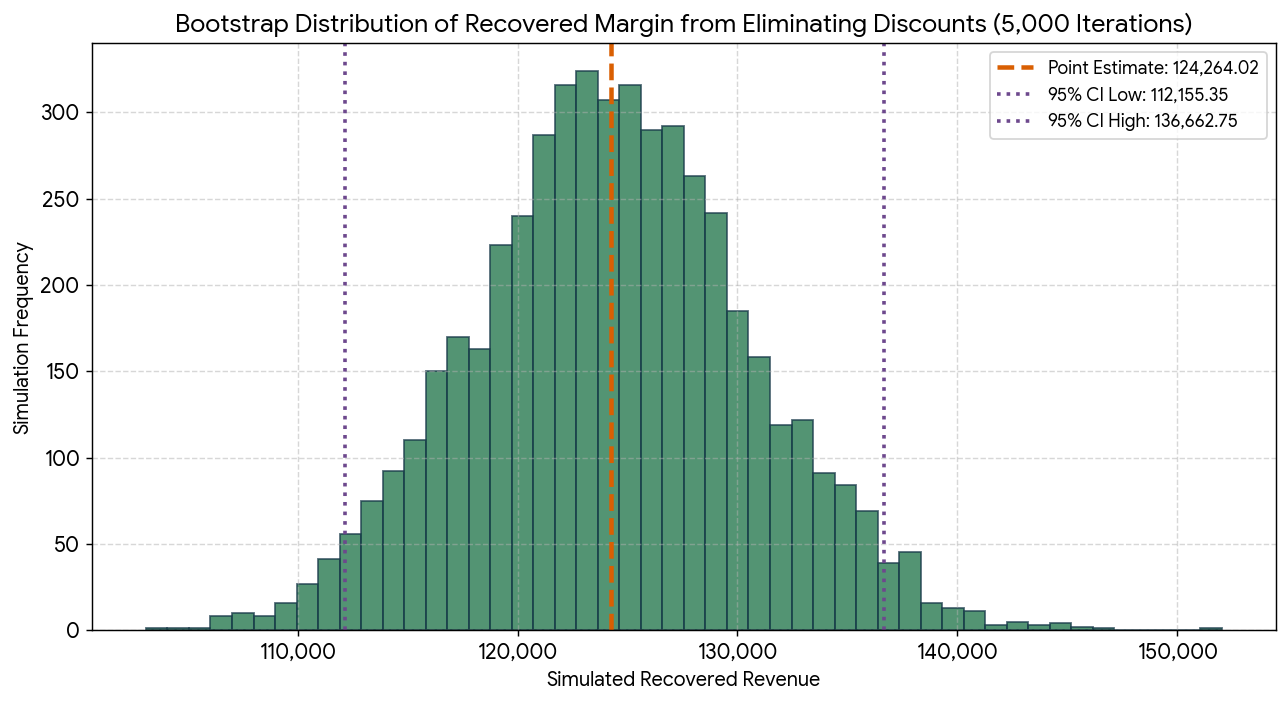

In [9]:
N_SIM = 5000
np.random.seed(SEED)

observed_net = df['Total_Amount'].to_numpy()
counterfactual_gross = (df['Unit_Price'] * df['Quantity']).to_numpy()
observed_discount = df['Discount_Amount'].to_numpy()

n_records = len(df)
recovered_sims = np.array([observed_discount[np.random.randint(0, n_records, size=n_records)].sum() for _ in range(N_SIM)])

actual_total_net = observed_net.sum()
actual_total_gross = counterfactual_gross.sum()
total_discount_given = observed_discount.sum()
ci_low, ci_high = np.percentile(recovered_sims, [2.5, 97.5])

sim_summary = save_table('25_no_discount_simulation', pd.DataFrame([
    {'Metric': 'Observed Net Revenue', 'Value': actual_total_net},
    {'Metric': 'Counterfactual Gross Revenue', 'Value': actual_total_gross},
    {'Metric': 'Simulated Recovered Revenue (Mean)', 'Value': recovered_sims.mean()},
    {'Metric': 'Recovered Revenue 95% CI Low', 'Value': ci_low},
    {'Metric': 'Recovered Revenue 95% CI High', 'Value': ci_high},
    {'Metric': 'Top-Line Revenue Lift Share', 'Value': total_discount_given / actual_total_net}
]), 'Bootstrap simulation of recovered revenue under full gross pricing.')

MARGIN_RATE = 0.60
cogs = actual_total_net * (1 - MARGIN_RATE)
net_income_before = actual_total_net - cogs
net_income_after = net_income_before + total_discount_given

impact_df = save_table('26_net_income_margin_impact', pd.DataFrame([
    {'Metric': 'Observed Net Revenue', 'Before_Removal': actual_total_net, 'After_Removal': actual_total_gross, 'Absolute_Change': total_discount_given, 'Relative_Change': total_discount_given / actual_total_net},
    {'Metric': 'Assumed Gross Margin Rate', 'Before_Removal': MARGIN_RATE, 'After_Removal': MARGIN_RATE, 'Absolute_Change': 0.0, 'Relative_Change': 0.0},
    {'Metric': 'Cost of Goods Sold (COGS)', 'Before_Removal': cogs, 'After_Removal': cogs, 'Absolute_Change': 0.0, 'Relative_Change': 0.0},
    {'Metric': 'Net Operating Income', 'Before_Removal': net_income_before, 'After_Removal': net_income_after, 'Absolute_Change': total_discount_given, 'Relative_Change': (net_income_after - net_income_before) / net_income_before}
]), 'Net operating income impact assuming 60% baseline gross margin and constant unit volume.')

plt.figure(figsize=(10, 5.5))
plt.hist(recovered_sims, bins=50, color='#197044', alpha=0.75, edgecolor='#193A4A')
plt.axvline(total_discount_given, color='#D95F02', linestyle='--', linewidth=2.5, label=f'Point Estimate: {total_discount_given:,.2f}')
plt.axvline(ci_low, color='#6D488D', linestyle=':', linewidth=2, label=f'95% CI Low: {ci_low:,.2f}')
plt.axvline(ci_high, color='#6D488D', linestyle=':', linewidth=2, label=f'95% CI High: {ci_high:,.2f}')
plt.xlabel('Simulated Recovered Revenue')
plt.ylabel('Simulation Frequency')
plt.title('Bootstrap Distribution of Recovered Margin from Eliminating Discounts (5,000 Iterations)')
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:,.0f}'))
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
save_figure('22_no_discount_recovered_distribution', 'Bootstrap distribution of recovered revenue.')

## 10. Verification and Integrity Assertions

In [10]:
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == EXPECTED_SHA256
pd.testing.assert_frame_equal(source_df, df, check_exact=True)
assert len(df) == 5000 and len(dev_index) + len(test_index) == len(df)
assert set(dev_index).isdisjoint(test_index)
assert df.iloc[dev_index].Date.max() < df.iloc[test_index].Date.min()
assert not set(['Order_ID', 'Customer_ID', 'Total_Amount', 'Customer_Rating', 'Delivery_Time_Days', 'Is_Returning_Customer']).intersection(model_features)
for name in TABLES:
    assert (OUTPUT_DIR / 'tables' / f'{name}.csv').is_file(), f'Missing table {name}'
for item in FIGURES:
    assert (OUTPUT_DIR / item['path']).is_file(), f"Missing figure {item['path']}"

print(f'All checks passed. Exported {len(TABLES)} tables and {len(FIGURES)} figures to {OUTPUT_DIR}/.')

All checks passed. Exported 26 tables and 24 figures to outputs/.
